<a href="https://colab.research.google.com/github/suryamanoj4/smai-a5/blob/main/SMAI_A5_Q2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Sentiment Analysis on IMDB with a Vanilla RNN**

In [3]:
!pip install -q datasets

In [4]:
import os
import re
import random
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [5]:
def load_imdb_data(seed=42):
    dataset = load_dataset("stanfordnlp/imdb")
    train_df = pd.DataFrame(dataset["train"])
    test_df = pd.DataFrame(dataset["test"])

    # Remove duplicate reviews inside the training split. IMDB contains
    # repeated review texts, and splitting before deduplication would place
    # the same review in both train and validation.
    train_df = (
        train_df
        .drop_duplicates(subset="text", keep="first")
        .reset_index(drop=True)
    )

    # The provided test split is kept as the final test set, but any training
    # review whose exact text also occurs in test must be removed to avoid
    # train-test leakage.
    test_texts = set(test_df["text"])
    train_df = (
        train_df[~train_df["text"].isin(test_texts)]
        .reset_index(drop=True)
    )

    train_df, val_df = train_test_split(
        train_df,
        test_size=0.15,
        random_state=seed,
        stratify=train_df["label"]
    )
    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    # Hard guarantees: no exact review text may appear in more than one split.
    train_texts = set(train_df["text"])
    val_texts = set(val_df["text"])
    assert not (train_texts & val_texts), "Train/validation text overlap"
    assert not (train_texts & test_texts), "Train/test text overlap"
    assert not (val_texts & test_texts), "Validation/test text overlap"

    return train_df, val_df, test_df

train_df, val_df, test_df = load_imdb_data(SEED)

print("Dataset loaded successfully!\n")

print(f"Training samples   : {len(train_df)}")
print(f"Validation samples : {len(val_df)}")
print(f"Test samples       : {len(test_df)}")

print("\nClass distribution:")

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    print(df["label"].value_counts().sort_index())


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset loaded successfully!

Training samples   : 21063
Validation samples : 3718
Test samples       : 25000

Class distribution:

Train:
label
0    10486
1    10577
Name: count, dtype: int64

Validation:
label
0    1851
1    1867
Name: count, dtype: int64

Test:
label
0    12500
1    12500
Name: count, dtype: int64


In [6]:
import html

def preprocess_text(text):
  text = html.unescape(text)
  text = re.sub(r"<[^>]+>"," ",text)
  text = text.lower()
  tokens = re.findall(r"\b[\w']+\b|[^\w\s]", text)
  return tokens

sample_review = train_df.loc[0,"text"]
print("Origin review:\n")
print(sample_review[:500])

sample_tokens = preprocess_text(sample_review)
print("\nTokens:\n")
print(sample_tokens[:50])
print("\nNumber of tokens:",len(sample_tokens))

Origin review:

I saw this movie at a drive-in in 1959. Until "Howard the Duck" I considered this the worst movie I had ever seen. This movie tried to combine all the genera in one; comedy, horror, teenage angst, and the hot rod that must have sired "My Mother, The Car." Maybe it deserves a second viewing to see if it is an accurate reflection of it's time.

Tokens:

['i', 'saw', 'this', 'movie', 'at', 'a', 'drive', '-', 'in', 'in', '1959', '.', 'until', '"', 'howard', 'the', 'duck', '"', 'i', 'considered', 'this', 'the', 'worst', 'movie', 'i', 'had', 'ever', 'seen', '.', 'this', 'movie', 'tried', 'to', 'combine', 'all', 'the', 'genera', 'in', 'one', ';', 'comedy', ',', 'horror', ',', 'teenage', 'angst', ',', 'and', 'the', 'hot']

Number of tokens: 81


In [7]:
MAX_VOCAB_SIZE = 10000
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"

PAD_IDX = 0
UNK_IDX = 1

def build_vocabulary(texts, max_vocab_size=10000):
    """
    build vocabulary from training texts only

    The vocabulary consists of:
        <pad> : index 0
        <unk> : index 1
        Most frequent tokens : indices 2 onwards
    """
    token_counts = Counter()
    for text in texts:
        tokens = preprocess_text(text)
        token_counts.update(tokens)

    most_common_tokens = token_counts.most_common(max_vocab_size)
    vocab = {
        PAD_TOKEN: PAD_IDX,
        UNK_TOKEN: UNK_IDX
    }
    for token, _ in most_common_tokens:
        if token not in vocab:
            vocab[token] = len(vocab)
    return vocab, token_counts

vocab, token_counts = build_vocabulary(
    train_df["text"],
    max_vocab_size=MAX_VOCAB_SIZE
)

print("Vocabulary size:", len(vocab))
print("Expected vocabulary size:", MAX_VOCAB_SIZE + 2)

print("\nSpecial token indices:")
print(PAD_TOKEN, ":", vocab[PAD_TOKEN])
print(UNK_TOKEN, ":", vocab[UNK_TOKEN])

print("\nMost frequent tokens:")
print(token_counts.most_common(20))

Vocabulary size: 10002
Expected vocabulary size: 10002

Special token indices:
<pad> : 0
<unk> : 1

Most frequent tokens:
[('the', 284222), ('.', 275822), (',', 233354), ('and', 138437), ('a', 137693), ('of', 123017), ('to', 114492), ('is', 90481), ('in', 79317), ('it', 66747), ('i', 65107), ('this', 64046), ('that', 58912), ('-', 56706), ('"', 55543), ('was', 40699), ('as', 39703), ('for', 37399), ('with', 37243), ('movie', 36748)]


In [8]:
MAX_SEQUENCE_LENGTH = 150

def encode_review(text, vocab, max_length=150):
    """
    convert a review into toke ids
    """

    tokens = preprocess_text(text)
    token_ids = [
        vocab.get(token, UNK_IDX)
        for token in tokens
    ]
    if len(token_ids) > max_length:
        token_ids = token_ids[:max_length]
    length = len(token_ids)
    padding_length = max_length - length
    token_ids = [PAD_IDX] * padding_length + token_ids
    return token_ids, length

encoded_sample, sample_length = encode_review(
    sample_review,
    vocab,
    MAX_SEQUENCE_LENGTH
)

print("Encoded sequence:", encoded_sample[:20], "...")
print("Encoded sequence shape:", len(encoded_sample))
print("Actual sequence length:", sample_length)
print("Number of padding tokens:", encoded_sample.count(PAD_IDX))

Encoded sequence: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0] ...
Encoded sequence shape: 150
Actual sequence length: 81
Number of padding tokens: 69


In [9]:
def encode_dataframe(df, vocab, max_length=150):
    sequences = []
    lengths = []
    original_lengths = []
    labels = []

    for text, label in zip(df["text"], df["label"]):
        tokens = preprocess_text(text)
        original_length = len(tokens)
        sequence, retained_length = encode_review(
            text,
            vocab,
            max_length
        )
        sequences.append(sequence)
        lengths.append(retained_length)
        original_lengths.append(original_length)
        labels.append(int(label))
    return sequences, lengths, original_lengths, labels

train_sequences, train_lengths, train_original_lengths, train_labels = \
    encode_dataframe(train_df, vocab, MAX_SEQUENCE_LENGTH)

val_sequences, val_lengths, val_original_lengths, val_labels = \
    encode_dataframe(val_df, vocab, MAX_SEQUENCE_LENGTH)

test_sequences, test_lengths, test_original_lengths, test_labels = \
    encode_dataframe(test_df, vocab, MAX_SEQUENCE_LENGTH)


print("Encoding completed successfully!")
print("Train:", len(train_sequences))
print("Validation:", len(val_sequences))
print("Test:", len(test_sequences))

print("\nExample encoded sequence:")
print(train_sequences[0][:20], "...")
print("Sequence length:", len(train_sequences[0]))
print("Actual review length:", train_lengths[0])
print("Original token length:", train_original_lengths[0])

Encoding completed successfully!
Train: 21063
Validation: 3718
Test: 25000

Example encoded sequence:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0] ...
Sequence length: 150
Actual review length: 81
Original token length: 81


In [10]:
length_stats = {
    "Train": train_original_lengths,
    "Validation": val_original_lengths,
    "Test": test_original_lengths
}

stats_rows = []
for split_name, lengths in length_stats.items():
    lengths = np.array(lengths)
    truncated_count = np.sum(lengths > MAX_SEQUENCE_LENGTH)
    stats_rows.append({
        "Split": split_name,
        "Total Reviews": len(lengths),
        "Mean Length": lengths.mean(),
        "Median Length": np.median(lengths),
        "Maximum Length": lengths.max(),
        "Truncated Reviews": truncated_count,
        "Truncation Fraction (%)": 100 * truncated_count / len(lengths)
    })

length_stats_df = pd.DataFrame(stats_rows)
display(length_stats_df.round(2))

,Split,Total Reviews,Mean Length,Median Length,Maximum Length,Truncated Reviews,Truncation Fraction (%)
0,Train,21063,270.18,201.0,2739,15252,72.41
1,Validation,3718,269.69,202.0,1662,2728,73.37
2,Test,25000,263.90,199.0,2588,17925,71.70


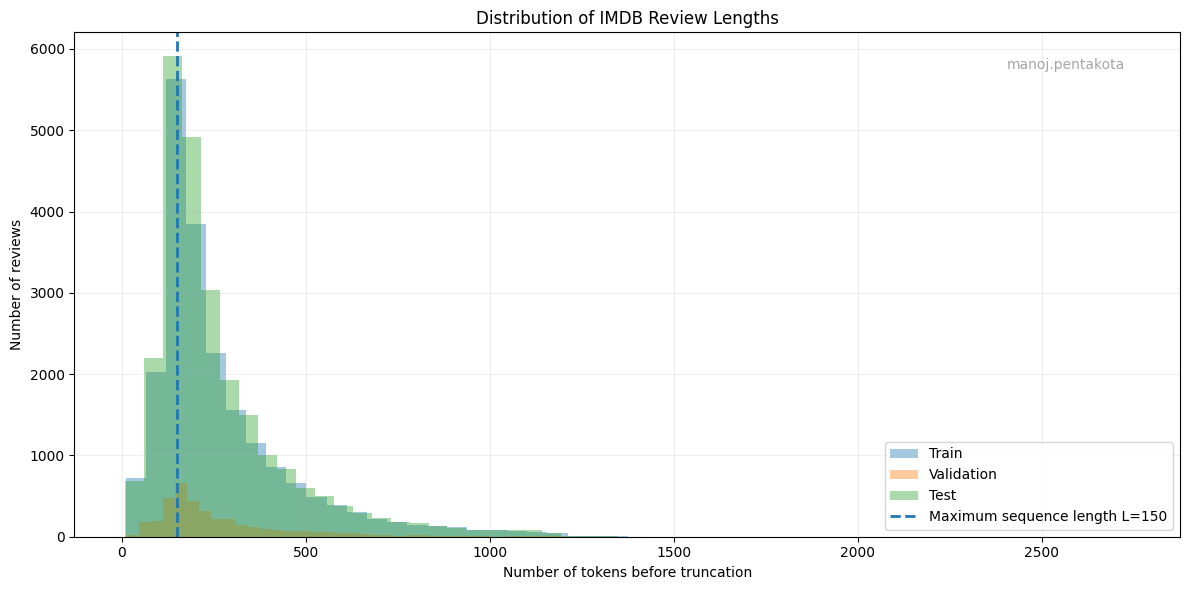

In [11]:
plt.figure(figsize=(12, 6))
for split_name, lengths in length_stats.items():
    plt.hist(
        lengths,
        bins=50,
        alpha=0.4,
        label=split_name
    )
plt.axvline(
    MAX_SEQUENCE_LENGTH,
    linestyle="--",
    linewidth=2,
    label=f"Maximum sequence length L={MAX_SEQUENCE_LENGTH}"
)

plt.title("Distribution of IMDB Review Lengths")
plt.xlabel("Number of tokens before truncation")
plt.ylabel("Number of reviews")
plt.legend()
plt.grid(alpha=0.2)
plt.text(
    0.95, 0.95, "manoj.pentakota",
    ha="right",
    va="top",
    transform=plt.gca().transAxes,
    fontsize=10,
    color="gray",
    alpha=0.7
)
plt.tight_layout()
plt.show()

In [12]:
class IMDBDataset(Dataset):
    """
    Dataset for IMDB sentiment classification
    """
    def __init__(self, sequences, lengths, labels):
        self.sequences = torch.tensor(
            sequences,
            dtype=torch.long
        )
        self.lengths = torch.tensor(
            lengths,
            dtype=torch.long
        )
        self.labels = torch.tensor(
            labels,
            dtype=torch.float32
        )
    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            self.sequences[idx],
            self.lengths[idx],
            self.labels[idx]
        )

train_dataset = IMDBDataset(
    train_sequences,
    train_lengths,
    train_labels
)

val_dataset = IMDBDataset(
    val_sequences,
    val_lengths,
    val_labels
)

test_dataset = IMDBDataset(
    test_sequences,
    test_lengths,
    test_labels
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 21063
Validation dataset: 3718
Test dataset: 25000


In [13]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

token_ids, lengths, labels = next(iter(train_loader))

print("Token IDs shape:", token_ids.shape)
print("Lengths shape:", lengths.shape)
print("Labels shape:", labels.shape)

print("Token IDs dtype:", token_ids.dtype)
print("Lengths dtype:", lengths.dtype)
print("Labels dtype:", labels.dtype)

print("\nSample lengths:", lengths[:10])
print("Sample labels:", labels[:10])

Token IDs shape: torch.Size([64, 150])
Lengths shape: torch.Size([64])
Labels shape: torch.Size([64])
Token IDs dtype: torch.int64
Lengths dtype: torch.int64
Labels dtype: torch.float32

Sample lengths: tensor([126, 150, 150, 126, 150, 150, 103,  50, 120, 150])
Sample labels: tensor([0., 0., 0., 1., 0., 1., 1., 0., 0., 1.])


In [14]:
assert all(len(seq) == MAX_SEQUENCE_LENGTH for seq in train_sequences)
assert all(len(seq) == MAX_SEQUENCE_LENGTH for seq in val_sequences)
assert all(len(seq) == MAX_SEQUENCE_LENGTH for seq in test_sequences)

assert vocab[PAD_TOKEN] == 0
assert vocab[UNK_TOKEN] == 1

assert set(train_labels) == {0, 1}
assert set(val_labels) == {0, 1}
assert set(test_labels) == {0, 1}

for seq, length in zip(train_sequences[:100], train_lengths[:100]):
    padding_count = MAX_SEQUENCE_LENGTH - length
    assert all(token == PAD_IDX for token in seq[:padding_count])

batch = next(iter(train_loader))

assert batch[0].shape == (BATCH_SIZE, MAX_SEQUENCE_LENGTH)
assert batch[1].shape == (BATCH_SIZE,)
assert batch[2].shape == (BATCH_SIZE,)

train_texts = set(train_df["text"])
val_texts = set(val_df["text"])
test_texts = set(test_df["text"])

print("Train-validation exact text overlap:", len(train_texts & val_texts))
print("Train-test exact text overlap:", len(train_texts & test_texts))
print("Validation-test exact text overlap:", len(val_texts & test_texts))

assert len(train_texts & val_texts) == 0
assert len(train_texts & test_texts) == 0
assert len(val_texts & test_texts) == 0
print("\nAll sanity checks passed — no exact-text overlap across splits.")

Train-validation exact text overlap: 0
Train-test exact text overlap: 0
Validation-test exact text overlap: 0

All sanity checks passed — no exact-text overlap across splits.


In [15]:
class RNNCellScratch(nn.Module):
    """
    vanilla RNN cell implemented from scratch.

    Computes:
        h_t = tanh(x_t @ W_ih.T + b_ih
                    + h_{t-1} @ W_hh.T + b_hh)

    Inputs:
        x_t     : [B, E]
        h_prev  : [B, H]

    Output:
        h_t     : [B, H]
    """

    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.weight_ih = nn.Parameter(torch.empty(hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(hidden_size))
        self.bias_hh = nn.Parameter(torch.empty(hidden_size))
        self.reset_parameters()

    def reset_parameters(self):
        """
        initialize all parameters uniformly in
        [-1/sqrt(H), 1/sqrt(H)]
        """
        bound = 1.0 / np.sqrt(self.hidden_size)
        nn.init.uniform_(self.weight_ih, -bound, bound)
        nn.init.uniform_(self.weight_hh, -bound, bound)
        nn.init.uniform_(self.bias_ih, -bound, bound)
        nn.init.uniform_(self.bias_hh, -bound, bound)

    def forward(self, x_t, h_prev):
        input_term = torch.matmul(x_t, self.weight_ih.T) + self.bias_ih
        hidden_term = torch.matmul(h_prev, self.weight_hh.T) + self.bias_hh
        h_t = torch.tanh(input_term + hidden_term)
        return h_t


INPUT_SIZE = 100
HIDDEN_SIZE = 64

cell = RNNCellScratch(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE
)
batch_size = 8
x_t = torch.randn(batch_size, INPUT_SIZE)
h_prev = torch.zeros(batch_size, HIDDEN_SIZE)
h_t = cell(x_t, h_prev)

print("Input shape:", x_t.shape)
print("Previous hidden state shape:", h_prev.shape)
print("Output hidden state shape:", h_t.shape)

print("\nParameter shapes:")
for name, param in cell.named_parameters():
    print(f"{name:15s}: {tuple(param.shape)}")

assert h_t.shape == (batch_size, HIDDEN_SIZE)

print("\nRNNCellScratch test passed!")

Input shape: torch.Size([8, 100])
Previous hidden state shape: torch.Size([8, 64])
Output hidden state shape: torch.Size([8, 64])

Parameter shapes:
weight_ih      : (64, 100)
weight_hh      : (64, 64)
bias_ih        : (64,)
bias_hh        : (64,)

RNNCellScratch test passed!


In [16]:
class RNNScratch(nn.Module):
    """
    vanilla RNN implemented by manually unrolling RNNCellScratch
    over the sequence dimension

    Input:
        x : [B, T, E]

    Returns:
        outputs : [B, T, H]  (hidden state at every timestep)
        h_final : [B, H]     (final hidden state)

    Optionally retains gradients on intermediate hidden states
    for gradient analysis
    """

    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.cell = RNNCellScratch(
            input_size=input_size,
            hidden_size=hidden_size
        )

    def forward(self, x, retain_hidden_grads=False):
        batch_size, sequence_length, input_size = x.shape
        h_t = torch.zeros(
            batch_size,
            self.hidden_size,
            device=x.device,
            dtype=x.dtype
        )
        hidden_states = []
        for t in range(sequence_length):
            x_t = x[:, t, :]
            h_t = self.cell(x_t, h_t)
            if retain_hidden_grads:
                h_t.retain_grad()
            hidden_states.append(h_t)

        outputs = torch.stack(
            hidden_states,
            dim=1
        )
        h_final = h_t
        return outputs, h_final

scratch_rnn = RNNScratch(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE
)

B = 8
T = 20
E = INPUT_SIZE

x = torch.randn(B, T, E)
outputs, h_final = scratch_rnn(x)

print("Input shape:", x.shape)
print("All hidden states shape:", outputs.shape)
print("Final hidden state shape:", h_final.shape)

assert outputs.shape == (B, T, HIDDEN_SIZE)
assert h_final.shape == (B, HIDDEN_SIZE)
assert torch.allclose(outputs[:, -1, :],h_final)

print("\nRNNScratch test passed!")

Input shape: torch.Size([8, 20, 100])
All hidden states shape: torch.Size([8, 20, 64])
Final hidden state shape: torch.Size([8, 64])

RNNScratch test passed!


In [17]:
torch_rnn = nn.RNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=1,
    nonlinearity="tanh",
    batch_first=True,
    bias=True
)

scratch_rnn = RNNScratch(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE
)

with torch.no_grad():
    scratch_rnn.cell.weight_ih.copy_(
        torch_rnn.weight_ih_l0
    )
    scratch_rnn.cell.weight_hh.copy_(
        torch_rnn.weight_hh_l0
    )
    scratch_rnn.cell.bias_ih.copy_(
        torch_rnn.bias_ih_l0
    )
    scratch_rnn.cell.bias_hh.copy_(
        torch_rnn.bias_hh_l0
    )

set_seed(SEED)

B = 8
T = 25
E = INPUT_SIZE

test_input = torch.randn(B, T, E)
torch_outputs, torch_h_n = torch_rnn(test_input)
scratch_outputs, scratch_h_final = scratch_rnn(test_input)

torch_h_final = torch_h_n[-1]

sequence_match = torch.allclose(
    scratch_outputs,
    torch_outputs,
    atol=1e-5,
    rtol=1e-5
)

final_hidden_match = torch.allclose(
    scratch_h_final,
    torch_h_final,
    atol=1e-5,
    rtol=1e-5
)

sequence_max_diff = (scratch_outputs - torch_outputs).abs().max().item()
final_hidden_max_diff = (scratch_h_final - torch_h_final).abs().max().item()

print("=" * 60)
print("SCRATCH RNN vs PYTORCH RNN CORRECTNESS TEST")
print("=" * 60)

print("\nFull sequence output:")
print("Scratch shape:", scratch_outputs.shape)
print("PyTorch shape:", torch_outputs.shape)
print("Maximum absolute difference:", sequence_max_diff)
print("Result:", "PASS" if sequence_match else "FAIL")

print("\nFinal hidden state:")
print("Scratch shape:", scratch_h_final.shape)
print("PyTorch shape:", torch_h_final.shape)
print("Maximum absolute difference:", final_hidden_max_diff)
print("Result:", "PASS" if final_hidden_match else "FAIL")

print("\n" + "=" * 60)

if sequence_match and final_hidden_match:
    print("OVERALL RESULT: PASS")
    print("Both implementations produce matching outputs.")
else:
    print("OVERALL RESULT: FAIL")
    print("Investigate the parameter mapping or implementation.")

print("=" * 60)

SCRATCH RNN vs PYTORCH RNN CORRECTNESS TEST

Full sequence output:
Scratch shape: torch.Size([8, 25, 64])
PyTorch shape: torch.Size([8, 25, 64])
Maximum absolute difference: 0.0
Result: PASS

Final hidden state:
Scratch shape: torch.Size([8, 64])
PyTorch shape: torch.Size([8, 64])
Maximum absolute difference: 0.0
Result: PASS

OVERALL RESULT: PASS
Both implementations produce matching outputs.


In [2]:
!pip install -q wandb

In [1]:
import os
import wandb
from dotenv import load_dotenv

load_dotenv()
WANDB_API_KEY = os.getenv("WANDB_API_KEY")

if not WANDB_API_KEY:
    raise ValueError("WANDB_API_KEY not found in .env file")

wandb.login(key=WANDB_API_KEY)
print("W&B authentication successful")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: suryamanojphy31 (suryamanojphy31-iiit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B authentication successful


In [18]:
class IMDBSentimentRNN(nn.Module):
    """
    sentiment classifier:
    Embedding -> Vanilla RNN -> Linear -> Sigmoid

    Uses pre-padding, so the final hidden state corresponds
    to the final timestep of the padded sequence
    """
    def __init__(
        self,
        vocab_size,
        embedding_dim=100,
        hidden_size=64,
        padding_idx=0
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx
        )
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=1,
            nonlinearity="tanh",
            batch_first=True
        )
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, token_ids):
        embeddings = self.embedding(token_ids)
        outputs, h_n = self.rnn(embeddings)
        h_final = h_n[-1]
        logits = self.fc(h_final).squeeze(-1)
        return logits

model = IMDBSentimentRNN(
    vocab_size=len(vocab),
    embedding_dim=100,
    hidden_size=64,
    padding_idx=PAD_IDX
).to(DEVICE)

print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", total_params)
print("Trainable parameters:", trainable_params)

IMDBSentimentRNN(
  (embedding): Embedding(10002, 100, padding_idx=0)
  (rnn): RNN(100, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

Total parameters: 1010889
Trainable parameters: 1010889


In [19]:
CONFIG = {
    "seed": SEED,
    "max_sequence_length": MAX_SEQUENCE_LENGTH,
    "vocab_size": len(vocab),
    "embedding_dim": 100,
    "hidden_size": 64,
    "batch_size": BATCH_SIZE,
    "epochs": 10,
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "loss": "BCEWithLogitsLoss",
    "model": "Vanilla RNN",
    "padding": "Pre-padding",
    "gradient_clipping": False,
    "dataset": "IMDB",
    "train_size": len(train_dataset),
    "validation_size": len(val_dataset),
    "test_size": len(test_dataset)
}

print(json.dumps(CONFIG, indent=4))

{
    "seed": 42,
    "max_sequence_length": 150,
    "vocab_size": 10002,
    "embedding_dim": 100,
    "hidden_size": 64,
    "batch_size": 64,
    "epochs": 10,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "BCEWithLogitsLoss",
    "model": "Vanilla RNN",
    "padding": "Pre-padding",
    "gradient_clipping": false,
    "dataset": "IMDB",
    "train_size": 21063,
    "validation_size": 3718,
    "test_size": 25000
}


In [20]:
wandb_run = wandb.init(
    project="SMAI-A5-IMDB-RNN",
    name="main_rnn_seed42",
    config=CONFIG,
    tags=["main-run", "vanilla-rnn", "seed-42"]
)

print("W&B run initialized!")
print("Project:", wandb_run.project)
print("Run name:", wandb_run.name)
print("Run URL:", wandb_run.url)

W&B run initialized!
Project: SMAI-A5-IMDB-RNN
Run name: main_rnn_seed42
Run URL: https://wandb.ai/suryamanojphy31-iiit-hyderabad/SMAI-A5-IMDB-RNN/runs/934c9q2p


In [21]:
criterion = nn.BCEWithLogitsLoss()

def run_epoch(model, loader, criterion, optimizer=None, device=DEVICE):
    """
    Run one training or validation epoch
    """
    is_training = optimizer is not None
    if is_training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for token_ids, lengths, labels in loader:
        token_ids = token_ids.to(device)
        labels = labels.to(device)
        if is_training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(is_training):
            logits = model(token_ids)
            loss = criterion(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).float()
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples
    return average_loss, accuracy

print("Training and validation functions defined!")

Training and validation functions defined!


In [22]:
CHECKPOINT_DIR = "/content/imdb_rnn_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
BEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_main_rnn.pth"
)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=CONFIG["learning_rate"]
)
history = []
best_val_accuracy = -1.0
best_epoch = -1
overall_start_time = time.time()
for epoch in range(1, CONFIG["epochs"] + 1):
    epoch_start_time = time.time()
    train_loss, train_accuracy = run_epoch(
        model=model,
        loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=DEVICE
    )
    val_loss, val_accuracy = run_epoch(
        model=model,
        loader=val_loader,
        criterion=criterion,
        optimizer=None,
        device=DEVICE
    )
    epoch_time = time.time() - epoch_start_time
    epoch_results = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "epoch_time_sec": epoch_time
    }
    history.append(epoch_results)
    wandb.log(epoch_results)
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_accuracy": best_val_accuracy,
                "config": CONFIG
            },
            BEST_CHECKPOINT_PATH
        )
        print(" -> Best checkpoint saved!")

    print(
        f"Epoch [{epoch:02d}/{CONFIG['epochs']}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

overall_training_time = time.time() - overall_start_time
history_df = pd.DataFrame(history)
history_path = os.path.join(CHECKPOINT_DIR,"main_rnn_history.csv")
history_df.to_csv(history_path, index=False)

wandb_run.summary["best_val_accuracy"] = best_val_accuracy
wandb_run.summary["best_epoch"] = best_epoch
wandb_run.summary["total_training_time_sec"] = overall_training_time

print("\nTraining completed!")
print("Best validation accuracy:", best_val_accuracy)
print("Best epoch:", best_epoch)
print(f"Total training time: {overall_training_time:.2f} seconds")
print("Checkpoint:", BEST_CHECKPOINT_PATH)
print("History CSV:", history_path)

 -> Best checkpoint saved!
Epoch [01/10] | Train Loss: 0.6898 | Train Acc: 0.5334 | Val Loss: 0.6683 | Val Acc: 0.5955 | Time: 3.79s
Epoch [02/10] | Train Loss: 0.6605 | Train Acc: 0.6069 | Val Loss: 0.6913 | Val Acc: 0.5368 | Time: 2.93s
Epoch [03/10] | Train Loss: 0.6831 | Train Acc: 0.5560 | Val Loss: 0.6902 | Val Acc: 0.5360 | Time: 1.38s
 -> Best checkpoint saved!
Epoch [04/10] | Train Loss: 0.6581 | Train Acc: 0.6102 | Val Loss: 0.6523 | Val Acc: 0.6127 | Time: 1.13s
Epoch [05/10] | Train Loss: 0.6742 | Train Acc: 0.5807 | Val Loss: 0.6898 | Val Acc: 0.5342 | Time: 1.14s
Epoch [06/10] | Train Loss: 0.6655 | Train Acc: 0.5974 | Val Loss: 0.6921 | Val Acc: 0.5535 | Time: 1.12s
Epoch [07/10] | Train Loss: 0.6366 | Train Acc: 0.6357 | Val Loss: 0.6812 | Val Acc: 0.5901 | Time: 1.13s
 -> Best checkpoint saved!
Epoch [08/10] | Train Loss: 0.5838 | Train Acc: 0.6946 | Val Loss: 0.6527 | Val Acc: 0.6334 | Time: 1.19s
 -> Best checkpoint saved!
Epoch [09/10] | Train Loss: 0.5397 | Train A

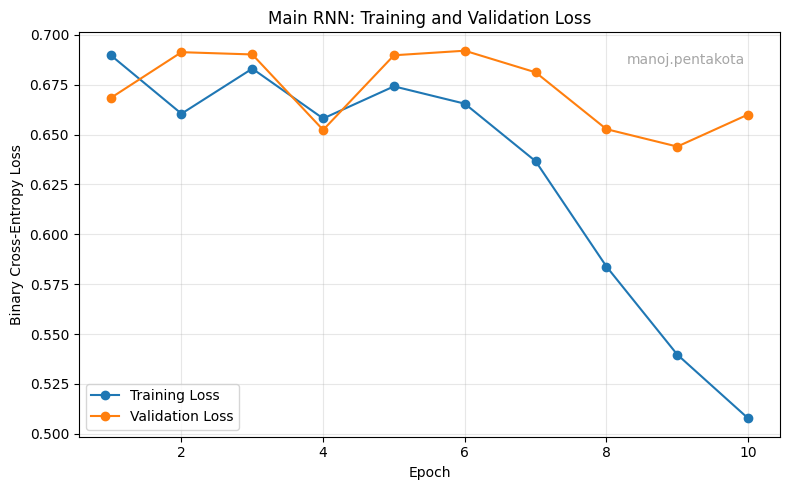

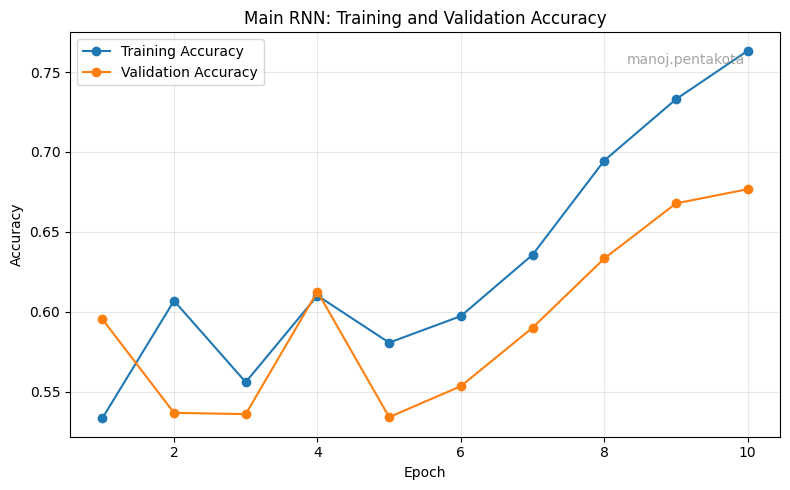

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)
plt.title("Main RNN: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.text(
    0.95, 0.95, "manoj.pentakota",
    ha="right",
    va="top",
    transform=plt.gca().transAxes,
    fontsize=10,
    color="gray",
    alpha=0.7
)
plt.tight_layout()
loss_plot_path = os.path.join(
    CHECKPOINT_DIR,
    "main_rnn_loss.png"
)
plt.savefig(loss_plot_path, dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)
plt.title("Main RNN: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.text(
    0.95, 0.95, "manoj.pentakota",
    ha="right",
    va="top",
    transform=plt.gca().transAxes,
    fontsize=10,
    color="gray",
    alpha=0.7
)
plt.tight_layout()
accuracy_plot_path = os.path.join(
    CHECKPOINT_DIR,
    "main_rnn_accuracy.png"
)
plt.savefig(accuracy_plot_path, dpi=150)
plt.show()

wandb.log({
    "training_loss_curve": wandb.Image(loss_plot_path),
    "training_accuracy_curve": wandb.Image(accuracy_plot_path)
})

In [24]:
checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best checkpoint")
print("Best epoch:", checkpoint["epoch"])
print("Best validation accuracy:", checkpoint["best_val_accuracy"])

Loaded best checkpoint
Best epoch: 10
Best validation accuracy: 0.6767079074771383


In [25]:
def evaluate_model(model, loader, device=DEVICE):
    """
    evaluate a binary classifier
    """
    model.eval()
    all_labels = []
    all_predictions = []
    all_probabilities = []
    with torch.no_grad():
        for token_ids, lengths, labels in loader:
            token_ids = token_ids.to(device)
            logits = model(token_ids)
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).long()
            all_labels.extend(labels.cpu().numpy().astype(int))
            all_predictions.extend(predictions.cpu().numpy().astype(int))
            all_probabilities.extend(probabilities.cpu().numpy())

    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)
    all_probabilities = np.array(all_probabilities)
    metrics = {
        "accuracy": accuracy_score(
            all_labels,
            all_predictions
        ),
        "precision": precision_score(
            all_labels,
            all_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            all_labels,
            all_predictions,
            zero_division=0
        ),
        "f1": f1_score(
            all_labels,
            all_predictions,
            zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            all_labels,
            all_predictions
        )
    }

    return {
        "metrics": metrics,
        "labels": all_labels,
        "predictions": all_predictions,
        "probabilities": all_probabilities
    }

test_results = evaluate_model(model,test_loader)
test_metrics = test_results["metrics"]

print("TEST RESULTS")
print("-" * 40)
for metric_name, metric_value in test_metrics.items():
    if metric_name != "confusion_matrix":
        print(f"{metric_name.capitalize():12s}: {metric_value:.4f}")

print("\nConfusion Matrix:")
print(test_metrics["confusion_matrix"])

TEST RESULTS
----------------------------------------
Accuracy    : 0.6702
Precision   : 0.6628
Recall      : 0.6928
F1          : 0.6775

Confusion Matrix:
[[8095 4405]
 [3840 8660]]


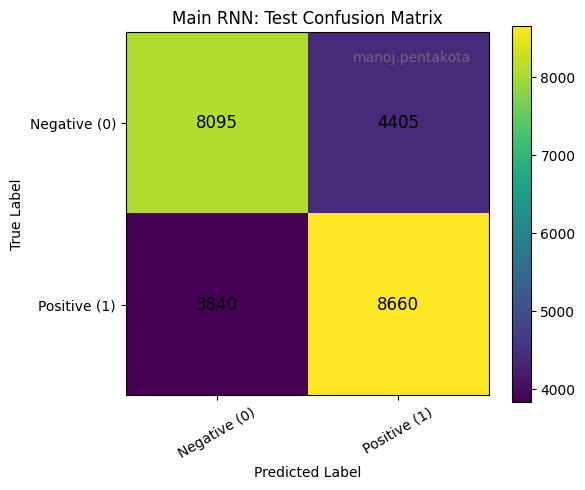

In [26]:
cm = test_metrics["confusion_matrix"]
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Main RNN: Test Confusion Matrix")
plt.colorbar()
classes = ["Negative (0)", "Positive (1)"]
plt.xticks(
    np.arange(2),
    classes,
    rotation=30
)
plt.yticks(
    np.arange(2),
    classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=12
        )

plt.text(
    0.95, 0.95, "manoj.pentakota",
    ha="right",
    va="top",
    transform=plt.gca().transAxes,
    fontsize=10,
    color="gray",
    alpha=0.7
)
plt.tight_layout()
cm_plot_path = os.path.join(
    CHECKPOINT_DIR,
    "main_rnn_confusion_matrix.png"
)

plt.savefig(cm_plot_path, dpi=150)
plt.show()

In [27]:
wandb.log({
    "test_accuracy": test_metrics["accuracy"],
    "test_precision": test_metrics["precision"],
    "test_recall": test_metrics["recall"],
    "test_f1": test_metrics["f1"],
    "test_confusion_matrix": wandb.Image(cm_plot_path)
})

wandb_run.summary["test_accuracy"] = test_metrics["accuracy"]
wandb_run.summary["test_precision"] = test_metrics["precision"]
wandb_run.summary["test_recall"] = test_metrics["recall"]
wandb_run.summary["test_f1"] = test_metrics["f1"]

print("Test metrics logged to W&B!")

Test metrics logged to W&B!


In [28]:
print(
    classification_report(
        test_results["labels"],
        test_results["predictions"],
        target_names=["Negative", "Positive"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Negative     0.6783    0.6476    0.6626     12500
    Positive     0.6628    0.6928    0.6775     12500

    accuracy                         0.6702     25000
   macro avg     0.6705    0.6702    0.6700     25000
weighted avg     0.6705    0.6702    0.6700     25000



In [29]:
main_results = {
    "experiment": "Main RNN",
    "seed": SEED,
    "best_epoch": best_epoch,
    "best_validation_accuracy": best_val_accuracy,
    "test_accuracy": test_metrics["accuracy"],
    "test_precision": test_metrics["precision"],
    "test_recall": test_metrics["recall"],
    "test_f1": test_metrics["f1"],
    "training_time_sec": overall_training_time,
    "parameters": trainable_params,
    "checkpoint": BEST_CHECKPOINT_PATH
}

main_results_df = pd.DataFrame([main_results])
main_results_path = os.path.join(
    CHECKPOINT_DIR,
    "main_rnn_results.csv"
)
main_results_df.to_csv(
    main_results_path,
    index=False
)

display(main_results_df.round(4))
wandb.finish()
print("\nMain run completed and logged.")
print("Results saved at:", main_results_path)

,experiment,seed,best_epoch,best_validation_accuracy,test_accuracy,test_precision,test_recall,test_f1,training_time_sec,parameters,checkpoint
0,Main RNN,42,10,0.6767,0.6702,0.6628,0.6928,0.6775,16.2891,1010889,/content/imdb_rnn_checkpoints/best_main_rnn.pth


epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,█▆▂▁▁▁▁▁▁▁
test_accuracy,▁
test_f1,▁
test_precision,▁
test_recall,▁
train_accuracy,▁▃▂▃▂▃▄▆▇█
train_loss,█▇█▇▇▇▆▄▂▁
val_accuracy,▄▁▁▅▁▂▄▆██
val_loss,▅██▂██▆▂▁▃
best_epoch,10



Main run completed and logged.
Results saved at: /content/imdb_rnn_checkpoints/main_rnn_results.csv


In [30]:
class IMDBSentimentRNNScratch(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=100,
        hidden_size=64,
        padding_idx=0
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )
        self.rnn = RNNScratch(
            input_size=embedding_dim,
            hidden_size=hidden_size
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, token_ids):
        embeddings = self.embedding(token_ids)
        outputs, h_final = self.rnn(embeddings)
        logits = self.fc(h_final).squeeze(-1)
        return logits

In [31]:
import time
import copy

def train_comparison_model(
    model,
    model_name,
    train_loader,
    val_loader,
    epochs=10,
    lr=1e-3,
    wandb_run=None
):
    model = model.to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "epoch_time": []
    }
    best_val_acc = 0.0
    best_state = None
    total_start = time.time()

    print(f"\nTraining {model_name}")
    print("-" * 60)

    for epoch in range(epochs):
        epoch_start = time.time()
        train_loss, train_acc = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer=optimizer,
            device=DEVICE
        )
        val_loss, val_acc = run_epoch(
            model,
            val_loader,
            criterion,
            optimizer=None,
            device=DEVICE
        )
        epoch_time = time.time() - epoch_start

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)

        if wandb_run is not None:
            wandb_run.log({
                "epoch": epoch + 1,
                "train_loss": train_loss,
                "train_accuracy": train_acc,
                "val_loss": val_loss,
                "val_accuracy": val_acc,
                "epoch_time_sec": epoch_time
            })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Time: {epoch_time:.2f}s"
        )

    total_time = time.time() - total_start
    model.load_state_dict(best_state)
    return model, history, best_val_acc, total_time

In [32]:
set_seed(SEED)

scratch_wandb_run = wandb.init(
    project="SMAI-A5-IMDB-RNN",
    name=f"scratch_vs_builtin_scratch_seed{SEED}",
    config={
        "experiment": "scratch_vs_builtin",
        "model": "RNNScratch",
        "seed": SEED,
        "epochs": 10,
        "learning_rate": 1e-3,
        "batch_size": BATCH_SIZE,
        "max_sequence_length": MAX_SEQUENCE_LENGTH,
        "vocab_size": len(vocab)
    },
    tags=["scratch-vs-builtin", "scratch", f"seed-{SEED}"],
    reinit="finish_previous"
)

scratch_model = IMDBSentimentRNNScratch(
    vocab_size=len(vocab),
    embedding_dim=100,
    hidden_size=64,
    padding_idx=PAD_IDX
)

scratch_model, scratch_history, scratch_best_val_acc, scratch_total_time = (
    train_comparison_model(
        model=scratch_model,
        model_name="Scratch RNN",
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=10,
        lr=1e-3,
        wandb_run=scratch_wandb_run
    )
)


Training Scratch RNN
------------------------------------------------------------
Epoch 01/10 | Train Loss: 0.6963 | Train Acc: 0.5148 | Val Loss: 0.6942 | Val Acc: 0.5237 | Time: 24.30s
Epoch 02/10 | Train Loss: 0.6741 | Train Acc: 0.5825 | Val Loss: 0.6936 | Val Acc: 0.5118 | Time: 23.31s
Epoch 03/10 | Train Loss: 0.6603 | Train Acc: 0.6054 | Val Loss: 0.6852 | Val Acc: 0.5586 | Time: 22.42s
Epoch 04/10 | Train Loss: 0.6136 | Train Acc: 0.6701 | Val Loss: 0.6311 | Val Acc: 0.6584 | Time: 23.23s
Epoch 05/10 | Train Loss: 0.5880 | Train Acc: 0.6924 | Val Loss: 0.6522 | Val Acc: 0.6356 | Time: 23.26s
Epoch 06/10 | Train Loss: 0.5413 | Train Acc: 0.7347 | Val Loss: 0.6670 | Val Acc: 0.6302 | Time: 23.25s
Epoch 07/10 | Train Loss: 0.5701 | Train Acc: 0.7142 | Val Loss: 0.6343 | Val Acc: 0.6910 | Time: 22.52s
Epoch 08/10 | Train Loss: 0.5286 | Train Acc: 0.7437 | Val Loss: 0.6535 | Val Acc: 0.6522 | Time: 23.14s
Epoch 09/10 | Train Loss: 0.4812 | Train Acc: 0.7787 | Val Loss: 0.6376 | Val

In [33]:
scratch_test_results = evaluate_model(
    scratch_model,
    test_loader,
    device=DEVICE
)
builtin_test_results = main_results

scratch_wandb_run.log({
    "scratch_test_accuracy": scratch_test_results["metrics"]["accuracy"],
    "scratch_test_precision": scratch_test_results["metrics"]["precision"],
    "scratch_test_recall": scratch_test_results["metrics"]["recall"],
    "scratch_test_f1": scratch_test_results["metrics"]["f1"],
    "builtin_test_accuracy": builtin_test_results["test_accuracy"],
    "builtin_test_precision": builtin_test_results["test_precision"],
    "builtin_test_recall": builtin_test_results["test_recall"],
    "builtin_test_f1": builtin_test_results["test_f1"],
    "scratch_average_epoch_time_sec": float(np.mean(scratch_history["epoch_time"])),
    "builtin_average_epoch_time_sec": float(np.mean([row["epoch_time_sec"] for row in history])),
    "scratch_total_training_time_sec": scratch_total_time,
    "builtin_total_training_time_sec": builtin_test_results["training_time_sec"]
})
scratch_wandb_run.summary["scratch_test_accuracy"] = scratch_test_results["metrics"]["accuracy"]
scratch_wandb_run.summary["builtin_test_accuracy"] = builtin_test_results["test_accuracy"]
scratch_wandb_run.finish()


builtin_average_epoch_time_sec,▁
builtin_test_accuracy,▁
builtin_test_f1,▁
builtin_test_precision,▁
builtin_test_recall,▁
builtin_total_training_time_sec,▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,█▄▁▄▄▄▁▄▄▃
scratch_average_epoch_time_sec,▁
scratch_test_accuracy,▁
+8,...


In [34]:
print("Scratch results:")
print(scratch_test_results)

print("\nBuilt-in results:")
print(builtin_test_results)

Scratch results:
{'metrics': {'accuracy': 0.69628, 'precision': 0.6752374830369259, 'recall': 0.75632, 'f1': 0.7134825100939587, 'confusion_matrix': array([[7953, 4547],
       [3046, 9454]])}, 'labels': array([0, 0, 0, ..., 1, 1, 1], shape=(25000,)), 'predictions': array([1, 1, 0, ..., 1, 1, 0], shape=(25000,)), 'probabilities': array([0.61488473, 0.6880109 , 0.08605795, ..., 0.8441768 , 0.73221886,
       0.3147911 ], shape=(25000,), dtype=float32)}

Built-in results:
{'experiment': 'Main RNN', 'seed': 42, 'best_epoch': 10, 'best_validation_accuracy': 0.6767079074771383, 'test_accuracy': 0.6702, 'test_precision': 0.6628396479142747, 'test_recall': 0.6928, 'test_f1': 0.6774887541560728, 'training_time_sec': 16.28913116455078, 'parameters': 1010889, 'checkpoint': '/content/imdb_rnn_checkpoints/best_main_rnn.pth'}


In [35]:
print("Scratch RNN Test Accuracy:",
      scratch_test_results["metrics"]["accuracy"])

print("Built-in RNN Test Accuracy:",
      builtin_test_results["test_accuracy"])

Scratch RNN Test Accuracy: 0.69628
Built-in RNN Test Accuracy: 0.6702


In [36]:
print("Scratch history type:", type(scratch_history))
print("Scratch history:")
print(scratch_history)

print("\nMain history type:", type(history))
print("Main history:")
print(history[:2] if isinstance(history, list) else history)

Scratch history type: <class 'dict'>
Scratch history:
{'train_loss': [0.6963014234755333, 0.674104389780772, 0.6602915228361169, 0.6135827881207874, 0.5879744683547854, 0.5412897142324614, 0.5700642896876887, 0.5285672316061422, 0.4811632651235226, 0.43341703777531015], 'train_acc': [0.514836443051797, 0.582538099985757, 0.6054218297488487, 0.6701324597635664, 0.6923989934957033, 0.7347006599249869, 0.7141907610501828, 0.7436737406827137, 0.7787114845938375, 0.81018848217253], 'val_loss': [0.6941865611422633, 0.6936334411965832, 0.6851781885620084, 0.6310594770586446, 0.6521925771666061, 0.6670484673021428, 0.6342541209595892, 0.6534656416093745, 0.6376380322119316, 0.6545782232874501], 'val_acc': [0.5236686390532544, 0.5118343195266272, 0.5586336740182895, 0.6584185045723507, 0.6355567509413663, 0.6301775147928994, 0.6909628832705755, 0.6522323830016138, 0.6890801506186122, 0.6869284561592254], 'epoch_time': [24.29722809791565, 23.30677604675293, 22.416213512420654, 23.231197118759155

In [37]:
comparison_df = pd.DataFrame([
    {
        "Model": "Scratch RNN",
        "Best Validation Accuracy": scratch_best_val_acc,
        "Test Accuracy": scratch_test_results["metrics"]["accuracy"],
        "Average Epoch Time (sec)": np.mean(scratch_history["epoch_time"]),
        "Total Training Time (sec)": scratch_total_time,
        "Parameters": sum(p.numel() for p in scratch_model.parameters())
    },
    {
        "Model": "PyTorch nn.RNN",
        "Best Validation Accuracy": builtin_test_results["best_validation_accuracy"],
        "Test Accuracy": builtin_test_results["test_accuracy"],
        "Average Epoch Time (sec)": np.mean(
            [row["epoch_time_sec"] for row in history]
        ),
        "Total Training Time (sec)": builtin_test_results["training_time_sec"],
        "Parameters": sum(p.numel() for p in model.parameters())
    }
])

display(comparison_df)

,Model,Best Validation Accuracy,Test Accuracy,Average Epoch Time (sec),Total Training Time (sec),Parameters
0,Scratch RNN,0.690963,0.69628,23.161927,231.639388,1010889
1,PyTorch nn.RNN,0.676708,0.67020,1.611953,16.289131,1010889


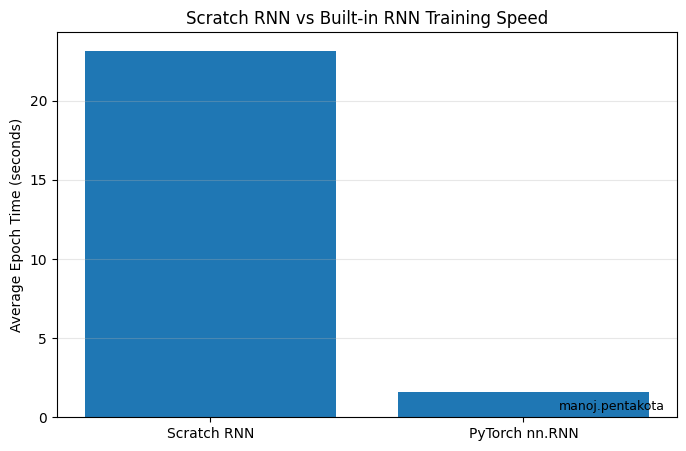

In [38]:
plt.figure(figsize=(8, 5))
plt.bar(
    comparison_df["Model"],
    comparison_df["Average Epoch Time (sec)"]
)
plt.ylabel("Average Epoch Time (seconds)")
plt.title("Scratch RNN vs Built-in RNN Training Speed")
plt.grid(axis="y", alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.show()

In [39]:
def create_loaders_for_length(max_length, batch_size=64):
    def encode_split(df):
        sequences = []
        lengths = []
        labels = []
        for _, row in df.iterrows():
            sequence, length = encode_review(
                row["text"],
                vocab,
                max_length=max_length
            )
            sequences.append(sequence)
            lengths.append(length)
            labels.append(row["label"])
        return sequences, lengths, labels

    train_sequences, train_lengths, train_labels = encode_split(train_df)
    val_sequences, val_lengths, val_labels = encode_split(val_df)
    test_sequences, test_lengths, test_labels = encode_split(test_df)
    train_dataset = IMDBDataset(
        train_sequences, train_lengths, train_labels
    )
    val_dataset = IMDBDataset(
        val_sequences, val_lengths, val_labels
    )
    test_dataset = IMDBDataset(
        test_sequences, test_lengths, test_labels
    )
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )
    return train_loader, val_loader, test_loader

In [40]:

import copy
import time
import os

def run_sequence_length_experiment(max_length, seed):
    set_seed(seed)

    train_loader, val_loader, test_loader = create_loaders_for_length(
        max_length=max_length,
        batch_size=64
    )

    exp_model = IMDBSentimentRNN(
        vocab_size=len(vocab),
        embedding_dim=100,
        hidden_size=64,
        padding_idx=PAD_IDX
    ).to(DEVICE)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(exp_model.parameters(), lr=1e-3)

    config = {
        "experiment": "E1_sequence_length",
        "max_sequence_length": max_length,
        "vocab_size": len(vocab),
        "embedding_dim": 100,
        "hidden_size": 64,
        "batch_size": 64,
        "epochs": 10,
        "learning_rate": 1e-3,
        "optimizer": "Adam",
        "seed": seed
    }

    run = wandb.init(
        project="SMAI-A5-IMDB-RNN",
        name=f"E1_length{max_length}_seed{seed}",
        config=config,
        tags=["E1", "sequence-length", f"seed-{seed}"],
        reinit="finish_previous"
    )

    history_exp = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "epoch_time": []
    }

    best_val_acc = -1
    best_epoch = -1
    best_state = None

    total_start = time.time()

    for epoch in range(10):
        epoch_start = time.time()

        train_loss, train_acc = run_epoch(
            exp_model, train_loader, criterion,
            optimizer=optimizer, device=DEVICE
        )

        val_loss, val_acc = run_epoch(
            exp_model, val_loader, criterion,
            optimizer=None, device=DEVICE
        )

        epoch_time = time.time() - epoch_start

        history_exp["train_loss"].append(train_loss)
        history_exp["train_acc"].append(train_acc)
        history_exp["val_loss"].append(val_loss)
        history_exp["val_acc"].append(val_acc)
        history_exp["epoch_time"].append(epoch_time)

        wandb.log({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "epoch_time_sec": epoch_time
        })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = copy.deepcopy(exp_model.state_dict())

        print(
            f"L={max_length} | Seed={seed} | "
            f"Epoch {epoch+1}/10 | "
            f"Train Acc={train_acc:.4f} | "
            f"Val Acc={val_acc:.4f} | "
            f"Time={epoch_time:.2f}s"
        )

    total_training_time = time.time() - total_start

    exp_model.load_state_dict(best_state)

    checkpoint_path = (
        f"/content/imdb_rnn_checkpoints/"
        f"E1_length{max_length}_seed{seed}.pth"
    )

    os.makedirs("/content/imdb_rnn_checkpoints", exist_ok=True)

    torch.save({
        "model_state_dict": best_state,
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "config": config,
        "history": history_exp
    }, checkpoint_path)

    test_results = evaluate_model(
        exp_model,
        test_loader,
        device=DEVICE
    )

    # Extract metrics from the nested dictionary
    test_metrics = test_results["metrics"]

    avg_epoch_time = np.mean(history_exp["epoch_time"])

    results = {
        "sequence_length": max_length,
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_acc,
        "test_accuracy": test_metrics["accuracy"],
        "test_precision": test_metrics["precision"],
        "test_recall": test_metrics["recall"],
        "test_f1": test_metrics["f1"],
        "average_epoch_time_sec": avg_epoch_time,
        "total_training_time_sec": total_training_time,
        "parameters": sum(p.numel() for p in exp_model.parameters()),
        "checkpoint": checkpoint_path
    }

    wandb.log({
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "test_accuracy": test_metrics["accuracy"],
        "test_precision": test_metrics["precision"],
        "test_recall": test_metrics["recall"],
        "test_f1": test_metrics["f1"],
        "average_epoch_time_sec": avg_epoch_time,
        "total_training_time_sec": total_training_time
    })

    wandb.finish()

    return results, history_exp, test_results

In [41]:
SEQUENCE_LENGTHS = [50, 150, 400]
EXPERIMENT_SEEDS = [42, 123]

e1_results = []
e1_histories = {}

for seq_length in SEQUENCE_LENGTHS:
    for seed in EXPERIMENT_SEEDS:
        print("\n" + "=" * 80)
        print(f"Starting E1: Length={seq_length}, Seed={seed}")
        print("=" * 80)
        results, exp_history, test_results = (
            run_sequence_length_experiment(
                max_length=seq_length,
                seed=seed
            )
        )
        e1_results.append(results)
        e1_histories[(seq_length, seed)] = exp_history
        print("\nRun completed:")
        print(results)


Starting E1: Length=50, Seed=42


L=50 | Seed=42 | Epoch 1/10 | Train Acc=0.5078 | Val Acc=0.5100 | Time=1.09s
L=50 | Seed=42 | Epoch 2/10 | Train Acc=0.5716 | Val Acc=0.5882 | Time=1.10s
L=50 | Seed=42 | Epoch 3/10 | Train Acc=0.5938 | Val Acc=0.5578 | Time=1.32s
L=50 | Seed=42 | Epoch 4/10 | Train Acc=0.5937 | Val Acc=0.5328 | Time=1.32s
L=50 | Seed=42 | Epoch 5/10 | Train Acc=0.6522 | Val Acc=0.6003 | Time=1.33s
L=50 | Seed=42 | Epoch 6/10 | Train Acc=0.6769 | Val Acc=0.5831 | Time=1.10s
L=50 | Seed=42 | Epoch 7/10 | Train Acc=0.6792 | Val Acc=0.5812 | Time=1.10s
L=50 | Seed=42 | Epoch 8/10 | Train Acc=0.6905 | Val Acc=0.5522 | Time=1.09s
L=50 | Seed=42 | Epoch 9/10 | Train Acc=0.7165 | Val Acc=0.6474 | Time=1.08s
L=50 | Seed=42 | Epoch 10/10 | Train Acc=0.7710 | Val Acc=0.6420 | Time=1.11s


average_epoch_time_sec,▁
best_epoch,▁
best_val_accuracy,▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,▁▂███▂▂▁▁▂
test_accuracy,▁
test_f1,▁
test_precision,▁
test_recall,▁
total_training_time_sec,▁
+4,...



Run completed:
{'sequence_length': 50, 'seed': 42, 'best_epoch': 9, 'best_val_accuracy': 0.6473910704679935, 'test_accuracy': 0.63864, 'test_precision': 0.6280100457970158, 'test_recall': 0.68016, 'test_f1': 0.6530455488132729, 'average_epoch_time_sec': np.float64(1.1640532732009887), 'total_training_time_sec': 11.659173727035522, 'parameters': 1010889, 'checkpoint': '/content/imdb_rnn_checkpoints/E1_length50_seed42.pth'}

Starting E1: Length=50, Seed=123


L=50 | Seed=123 | Epoch 1/10 | Train Acc=0.5078 | Val Acc=0.5086 | Time=1.10s
L=50 | Seed=123 | Epoch 2/10 | Train Acc=0.5601 | Val Acc=0.5992 | Time=1.12s
L=50 | Seed=123 | Epoch 3/10 | Train Acc=0.6062 | Val Acc=0.5707 | Time=1.20s
L=50 | Seed=123 | Epoch 4/10 | Train Acc=0.6273 | Val Acc=0.6081 | Time=1.34s
L=50 | Seed=123 | Epoch 5/10 | Train Acc=0.6689 | Val Acc=0.6165 | Time=1.39s
L=50 | Seed=123 | Epoch 6/10 | Train Acc=0.7131 | Val Acc=0.6482 | Time=1.18s
L=50 | Seed=123 | Epoch 7/10 | Train Acc=0.7229 | Val Acc=0.6568 | Time=1.11s
L=50 | Seed=123 | Epoch 8/10 | Train Acc=0.7572 | Val Acc=0.6657 | Time=1.14s
L=50 | Seed=123 | Epoch 9/10 | Train Acc=0.7830 | Val Acc=0.6641 | Time=1.11s
L=50 | Seed=123 | Epoch 10/10 | Train Acc=0.7943 | Val Acc=0.6748 | Time=1.12s


average_epoch_time_sec,▁
best_epoch,▁
best_val_accuracy,▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,▁▂▃▇█▃▁▂▁▁
test_accuracy,▁
test_f1,▁
test_precision,▁
test_recall,▁
total_training_time_sec,▁
+4,...


... (10 outputs left out)

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


L=400 | Seed=123 | Epoch 1/10 | Train Acc=0.5602 | Val Acc=0.6124 | Time=1.35s
L=400 | Seed=123 | Epoch 2/10 | Train Acc=0.6514 | Val Acc=0.6536 | Time=1.25s
L=400 | Seed=123 | Epoch 3/10 | Train Acc=0.7039 | Val Acc=0.7176 | Time=1.27s
L=400 | Seed=123 | Epoch 4/10 | Train Acc=0.6472 | Val Acc=0.5530 | Time=1.26s
L=400 | Seed=123 | Epoch 5/10 | Train Acc=0.6465 | Val Acc=0.5772 | Time=1.27s
L=400 | Seed=123 | Epoch 6/10 | Train Acc=0.7222 | Val Acc=0.7310 | Time=1.25s
L=400 | Seed=123 | Epoch 7/10 | Train Acc=0.7865 | Val Acc=0.7483 | Time=1.28s
L=400 | Seed=123 | Epoch 8/10 | Train Acc=0.7780 | Val Acc=0.7391 | Time=1.27s
L=400 | Seed=123 | Epoch 9/10 | Train Acc=0.7995 | Val Acc=0.6210 | Time=1.49s
L=400 | Seed=123 | Epoch 10/10 | Train Acc=0.6783 | Val Acc=0.6848 | Time=1.52s


average_epoch_time_sec,▁
best_epoch,▁
best_val_accuracy,▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,▄▁▂▁▂▁▂▁▇█
test_accuracy,▁
test_f1,▁
test_precision,▁
test_recall,▁
total_training_time_sec,▁
+4,...



Run completed:
{'sequence_length': 400, 'seed': 123, 'best_epoch': 7, 'best_val_accuracy': 0.7482517482517482, 'test_accuracy': 0.74656, 'test_precision': 0.6997407647440052, 'test_recall': 0.86376, 'test_f1': 0.7731471535982815, 'average_epoch_time_sec': np.float64(1.3210132837295532), 'total_training_time_sec': 13.231626272201538, 'parameters': 1010889, 'checkpoint': '/content/imdb_rnn_checkpoints/E1_length400_seed123.pth'}


In [42]:
e1_df = pd.DataFrame(e1_results)

e1_summary = (
    e1_df.groupby("sequence_length")
    .agg({
        "best_val_accuracy": ["mean", "std"],
        "test_accuracy": ["mean", "std"],
        "average_epoch_time_sec": ["mean", "std"],
        "total_training_time_sec": "mean",
        "parameters": "mean"
    })
)

display(e1_df)
display(e1_summary)

,sequence_length,seed,best_epoch,best_val_accuracy,test_accuracy,test_precision,test_recall,test_f1,average_epoch_time_sec,total_training_time_sec,parameters,checkpoint
0,50,42,9,0.647391,0.63864,0.628010,0.68016,0.653046,1.164053,11.659174,1010889,/content/imdb_rnn_checkpoints/E1_length50_seed...
1,50,123,10,0.674825,0.66264,0.684953,0.60232,0.640984,1.180650,11.829168,1010889,/content/imdb_rnn_checkpoints/E1_length50_seed...
2,150,42,6,0.657612,0.65204,0.708046,0.51744,0.597920,1.185081,11.869883,1010889,/content/imdb_rnn_checkpoints/E1_length150_see...
3,150,123,6,0.668101,0.66472,0.666370,0.65976,0.663049,1.215862,12.178257,1010889,/content/imdb_rnn_checkpoints/E1_length150_see...
4,400,42,8,0.735611,0.73128,0.753152,0.68808,0.719147,1.313093,13.152557,1010889,/content/imdb_rnn_checkpoints/E1_length400_see...
5,400,123,7,0.748252,0.74656,0.699741,0.86376,0.773147,1.321013,13.231626,1010889,/content/imdb_rnn_checkpoints/E1_length400_see...


best_val_accuracy           test_accuracy            \
                             mean       std          mean       std   
sequence_length                                                       
50                       0.661108  0.019399       0.65064  0.016971   
150                      0.662856  0.007417       0.65838  0.008966   
400                      0.741931  0.008939       0.73892  0.010805   

                average_epoch_time_sec           total_training_time_sec  \
                                  mean       std                    mean   
sequence_length                                                            
50                            1.172352  0.011736               11.744171   
150                           1.200471  0.021766               12.024070   
400                           1.317053  0.005600               13.192092   

                parameters  
                      mean  
sequence_length             
50               1010889.0  
150              1010889.0  
400              1010889.0

In [43]:
e1_df.to_csv("/content/E1_sequence_length_results.csv",index=False)
e1_summary.to_csv("/content/E1_sequence_length_summary.csv")

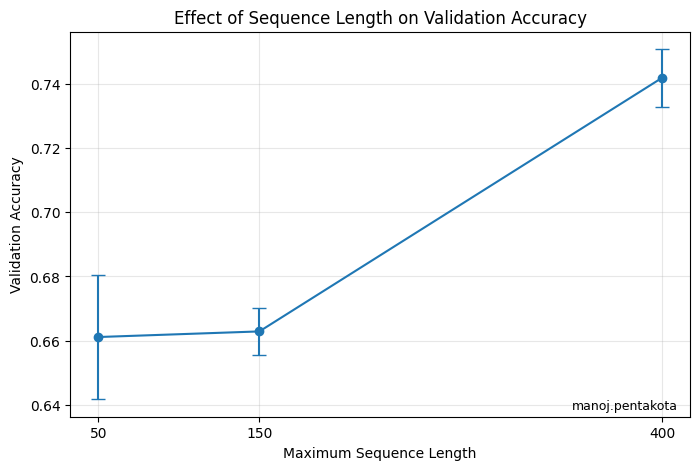

In [44]:
e1_plot_data = (
    e1_df.groupby("sequence_length")
    ["best_val_accuracy"]
    .agg(["mean", "std"])
)
plt.figure(figsize=(8, 5))
plt.errorbar(
    e1_plot_data.index,
    e1_plot_data["mean"],
    yerr=e1_plot_data["std"],
    marker="o",
    capsize=5
)
plt.xticks(SEQUENCE_LENGTHS)
plt.xlabel("Maximum Sequence Length")
plt.ylabel("Validation Accuracy")
plt.title("Effect of Sequence Length on Validation Accuracy")
plt.grid(alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E1_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

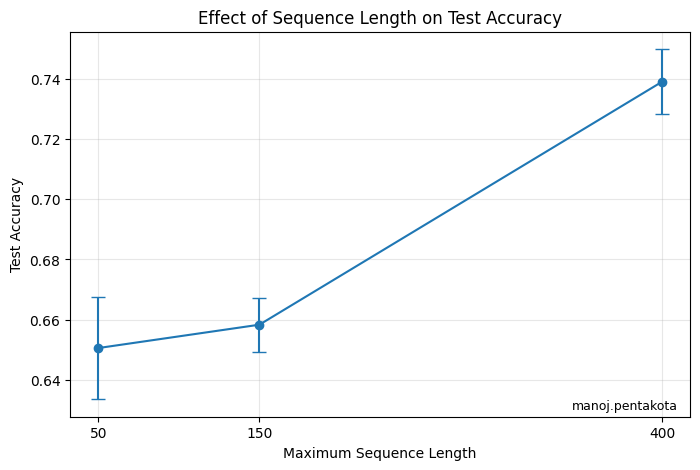

In [45]:
e1_test_plot_data = (
    e1_df.groupby("sequence_length")
    ["test_accuracy"]
    .agg(["mean", "std"])
)
plt.figure(figsize=(8, 5))
plt.errorbar(
    e1_test_plot_data.index,
    e1_test_plot_data["mean"],
    yerr=e1_test_plot_data["std"],
    marker="o",
    capsize=5
)
plt.xticks(SEQUENCE_LENGTHS)
plt.xlabel("Maximum Sequence Length")
plt.ylabel("Test Accuracy")
plt.title("Effect of Sequence Length on Test Accuracy")
plt.grid(alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E1_test_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

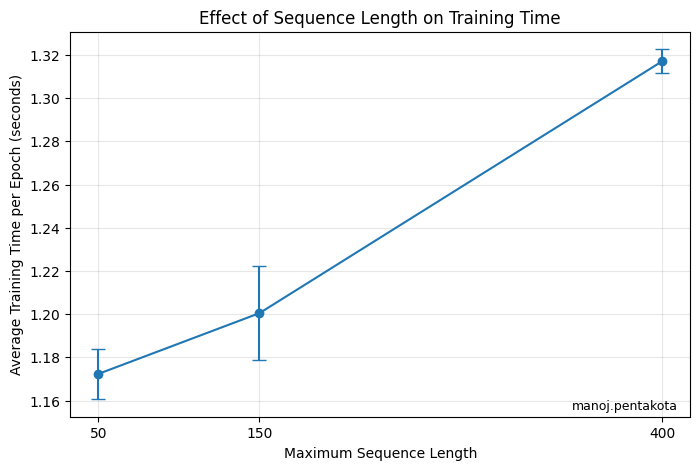

In [46]:
e1_time_data = (
    e1_df.groupby("sequence_length")
    ["average_epoch_time_sec"]
    .agg(["mean", "std"])
)
plt.figure(figsize=(8, 5))
plt.errorbar(
    e1_time_data.index,
    e1_time_data["mean"],
    yerr=e1_time_data["std"],
    marker="o",
    capsize=5
)
plt.xticks(SEQUENCE_LENGTHS)
plt.xlabel("Maximum Sequence Length")
plt.ylabel("Average Training Time per Epoch (seconds)")
plt.title("Effect of Sequence Length on Training Time")
plt.grid(alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E1_training_time.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [47]:

def run_hidden_size_experiment(hidden_size, seed):
    set_seed(seed)

    train_loader, val_loader, test_loader = create_loaders_for_length(
        max_length=150,
        batch_size=64
    )

    exp_model = IMDBSentimentRNN(
        vocab_size=len(vocab),
        embedding_dim=100,
        hidden_size=hidden_size,
        padding_idx=PAD_IDX
    ).to(DEVICE)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(exp_model.parameters(), lr=1e-3)

    config = {
        "experiment": "E2_hidden_size",
        "sequence_length": 150,
        "vocab_size": len(vocab),
        "embedding_dim": 100,
        "hidden_size": hidden_size,
        "batch_size": 64,
        "epochs": 10,
        "learning_rate": 1e-3,
        "optimizer": "Adam",
        "seed": seed
    }

    run = wandb.init(
        project="SMAI-A5-IMDB-RNN",
        name=f"E2_hidden{hidden_size}_seed{seed}",
        config=config,
        tags=["E2", "hidden-size", f"seed-{seed}"],
        reinit="finish_previous"
    )

    history_exp = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "epoch_time": []
    }

    best_val_acc = -1
    best_epoch = -1
    best_state = None

    total_start = time.time()

    for epoch in range(10):
        epoch_start = time.time()

        train_loss, train_acc = run_epoch(
            exp_model, train_loader, criterion,
            optimizer=optimizer, device=DEVICE
        )

        val_loss, val_acc = run_epoch(
            exp_model, val_loader, criterion,
            optimizer=None, device=DEVICE
        )

        epoch_time = time.time() - epoch_start

        history_exp["train_loss"].append(train_loss)
        history_exp["train_acc"].append(train_acc)
        history_exp["val_loss"].append(val_loss)
        history_exp["val_acc"].append(val_acc)
        history_exp["epoch_time"].append(epoch_time)

        wandb.log({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "epoch_time_sec": epoch_time
        })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = copy.deepcopy(exp_model.state_dict())

        print(
            f"H={hidden_size} | Seed={seed} | "
            f"Epoch {epoch+1}/10 | "
            f"Train Acc={train_acc:.4f} | "
            f"Val Acc={val_acc:.4f} | "
            f"Time={epoch_time:.2f}s"
        )

    total_training_time = time.time() - total_start

    exp_model.load_state_dict(best_state)

    os.makedirs("/content/imdb_rnn_checkpoints", exist_ok=True)

    checkpoint_path = (
        f"/content/imdb_rnn_checkpoints/"
        f"E2_hidden{hidden_size}_seed{seed}.pth"
    )

    torch.save({
        "model_state_dict": best_state,
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "config": config,
        "history": history_exp
    }, checkpoint_path)

    test_results = evaluate_model(
        exp_model,
        test_loader,
        device=DEVICE
    )

    # Extract nested test metrics
    test_metrics = test_results["metrics"]

    avg_epoch_time = np.mean(history_exp["epoch_time"])

    results = {
        "hidden_size": hidden_size,
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_acc,
        "test_accuracy": test_metrics["accuracy"],
        "test_precision": test_metrics["precision"],
        "test_recall": test_metrics["recall"],
        "test_f1": test_metrics["f1"],
        "average_epoch_time_sec": avg_epoch_time,
        "total_training_time_sec": total_training_time,
        "parameters": sum(
            p.numel() for p in exp_model.parameters()
        ),
        "checkpoint": checkpoint_path
    }

    wandb.log({
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "test_accuracy": test_metrics["accuracy"],
        "test_precision": test_metrics["precision"],
        "test_recall": test_metrics["recall"],
        "test_f1": test_metrics["f1"],
        "average_epoch_time_sec": avg_epoch_time,
        "total_training_time_sec": total_training_time,
        "total_parameters": results["parameters"]
    })

    wandb.finish()

    return results, history_exp, test_results

In [48]:
HIDDEN_SIZES = [32, 64, 128, 256]
EXPERIMENT_SEEDS = [42, 123]

e2_results = []
e2_histories = {}

for hidden_size in HIDDEN_SIZES:
    for seed in EXPERIMENT_SEEDS:
        print("\n" + "=" * 80)
        print(f"Starting E2: Hidden Size={hidden_size}, Seed={seed}")
        print("=" * 80)

        results, exp_history, test_results = (
            run_hidden_size_experiment(
                hidden_size=hidden_size,
                seed=seed
            )
        )
        e2_results.append(results)
        e2_histories[(hidden_size, seed)] = exp_history
        print("\nRun completed:")
        print(results)


Starting E2: Hidden Size=32, Seed=42


H=32 | Seed=42 | Epoch 1/10 | Train Acc=0.5139 | Val Acc=0.5126 | Time=1.30s
H=32 | Seed=42 | Epoch 2/10 | Train Acc=0.5663 | Val Acc=0.5600 | Time=1.16s
H=32 | Seed=42 | Epoch 3/10 | Train Acc=0.5988 | Val Acc=0.6027 | Time=1.13s
H=32 | Seed=42 | Epoch 4/10 | Train Acc=0.6638 | Val Acc=0.6248 | Time=1.14s
H=32 | Seed=42 | Epoch 5/10 | Train Acc=0.6952 | Val Acc=0.6619 | Time=1.12s
H=32 | Seed=42 | Epoch 6/10 | Train Acc=0.7199 | Val Acc=0.6522 | Time=1.11s
H=32 | Seed=42 | Epoch 7/10 | Train Acc=0.7527 | Val Acc=0.6708 | Time=1.39s
H=32 | Seed=42 | Epoch 8/10 | Train Acc=0.7844 | Val Acc=0.6684 | Time=1.40s
H=32 | Seed=42 | Epoch 9/10 | Train Acc=0.7996 | Val Acc=0.6676 | Time=1.36s
H=32 | Seed=42 | Epoch 10/10 | Train Acc=0.8060 | Val Acc=0.6877 | Time=1.16s


average_epoch_time_sec,▁
best_epoch,▁
best_val_accuracy,▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,▆▂▂▂▁▁██▇▂
test_accuracy,▁
test_f1,▁
test_precision,▁
test_recall,▁
total_parameters,▁
+5,...



Run completed:
{'hidden_size': 32, 'seed': 42, 'best_epoch': 10, 'best_val_accuracy': 0.6877353415814954, 'test_accuracy': 0.6878, 'test_precision': 0.6741856496252875, 'test_recall': 0.72688, 'test_f1': 0.6995419024521692, 'average_epoch_time_sec': np.float64(1.2267897605895997), 'total_training_time_sec': 12.291836261749268, 'parameters': 1004521, 'checkpoint': '/content/imdb_rnn_checkpoints/E2_hidden32_seed42.pth'}

Starting E2: Hidden Size=32, Seed=123


H=32 | Seed=123 | Epoch 1/10 | Train Acc=0.5132 | Val Acc=0.5334 | Time=1.16s
H=32 | Seed=123 | Epoch 2/10 | Train Acc=0.5753 | Val Acc=0.5939 | Time=1.13s
H=32 | Seed=123 | Epoch 3/10 | Train Acc=0.6503 | Val Acc=0.5925 | Time=1.13s
H=32 | Seed=123 | Epoch 4/10 | Train Acc=0.7067 | Val Acc=0.6563 | Time=1.15s
H=32 | Seed=123 | Epoch 5/10 | Train Acc=0.6647 | Val Acc=0.6684 | Time=1.17s
H=32 | Seed=123 | Epoch 6/10 | Train Acc=0.7315 | Val Acc=0.6791 | Time=1.31s
H=32 | Seed=123 | Epoch 7/10 | Train Acc=0.7629 | Val Acc=0.6945 | Time=1.39s
H=32 | Seed=123 | Epoch 8/10 | Train Acc=0.6595 | Val Acc=0.5414 | Time=1.41s
H=32 | Seed=123 | Epoch 9/10 | Train Acc=0.5870 | Val Acc=0.5484 | Time=1.16s
H=32 | Seed=123 | Epoch 10/10 | Train Acc=0.6161 | Val Acc=0.5702 | Time=1.14s


average_epoch_time_sec,▁
best_epoch,▁
best_val_accuracy,▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,▂▁▁▂▂▆██▂▁
test_accuracy,▁
test_f1,▁
test_precision,▁
test_recall,▁
total_parameters,▁
+5,...


... (15 outputs left out)


Run completed:
{'hidden_size': 256, 'seed': 42, 'best_epoch': 7, 'best_val_accuracy': 0.593329747175901, 'test_accuracy': 0.59924, 'test_precision': 0.6095751258722728, 'test_recall': 0.55208, 'test_f1': 0.5794047269216238, 'average_epoch_time_sec': np.float64(1.6869151592254639), 'total_training_time_sec': 16.889713525772095, 'parameters': 1092105, 'checkpoint': '/content/imdb_rnn_checkpoints/E2_hidden256_seed42.pth'}

Starting E2: Hidden Size=256, Seed=123


H=256 | Seed=123 | Epoch 1/10 | Train Acc=0.5230 | Val Acc=0.5247 | Time=1.88s
H=256 | Seed=123 | Epoch 2/10 | Train Acc=0.5359 | Val Acc=0.4954 | Time=1.70s
H=256 | Seed=123 | Epoch 3/10 | Train Acc=0.5279 | Val Acc=0.5116 | Time=1.63s
H=256 | Seed=123 | Epoch 4/10 | Train Acc=0.5296 | Val Acc=0.5169 | Time=1.62s
H=256 | Seed=123 | Epoch 5/10 | Train Acc=0.5469 | Val Acc=0.5309 | Time=1.62s
H=256 | Seed=123 | Epoch 6/10 | Train Acc=0.5743 | Val Acc=0.5390 | Time=1.63s
H=256 | Seed=123 | Epoch 7/10 | Train Acc=0.6149 | Val Acc=0.6261 | Time=1.62s
H=256 | Seed=123 | Epoch 8/10 | Train Acc=0.6456 | Val Acc=0.5627 | Time=1.72s
H=256 | Seed=123 | Epoch 9/10 | Train Acc=0.6463 | Val Acc=0.5578 | Time=1.81s
H=256 | Seed=123 | Epoch 10/10 | Train Acc=0.6719 | Val Acc=0.5538 | Time=1.71s


average_epoch_time_sec,▁
best_epoch,▁
best_val_accuracy,▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,█▃▁▁▁▁▁▄▆▄
test_accuracy,▁
test_f1,▁
test_precision,▁
test_recall,▁
total_parameters,▁
+5,...



Run completed:
{'hidden_size': 256, 'seed': 123, 'best_epoch': 7, 'best_val_accuracy': 0.6261430876815492, 'test_accuracy': 0.62352, 'test_precision': 0.6094104308390023, 'test_recall': 0.688, 'test_f1': 0.6463249661806704, 'average_epoch_time_sec': np.float64(1.6938503742218018), 'total_training_time_sec': 16.958205223083496, 'parameters': 1092105, 'checkpoint': '/content/imdb_rnn_checkpoints/E2_hidden256_seed123.pth'}


In [49]:
e2_df = pd.DataFrame(e2_results)
e2_summary = (
    e2_df.groupby("hidden_size")
    .agg({
        "best_val_accuracy": ["mean", "std"],
        "test_accuracy": ["mean", "std"],
        "test_f1": ["mean", "std"],
        "average_epoch_time_sec": ["mean", "std"],
        "total_training_time_sec": "mean",
        "parameters": "mean"
    })
)
display(e2_df)
display(e2_summary)

,hidden_size,seed,best_epoch,best_val_accuracy,test_accuracy,test_precision,test_recall,test_f1,average_epoch_time_sec,total_training_time_sec,parameters,checkpoint
0,32,42,10,0.687735,0.68780,0.674186,0.72688,0.699542,1.226790,12.291836,1004521,/content/imdb_rnn_checkpoints/E2_hidden32_seed...
1,32,123,7,0.694459,0.68564,0.686401,0.68360,0.684997,1.215456,12.176597,1004521,/content/imdb_rnn_checkpoints/E2_hidden32_seed...
2,64,42,6,0.657612,0.65204,0.708046,0.51744,0.597920,1.189248,11.921913,1010889,/content/imdb_rnn_checkpoints/E2_hidden64_seed...
3,64,123,6,0.668101,0.66472,0.666370,0.65976,0.663049,1.227825,12.298117,1010889,/content/imdb_rnn_checkpoints/E2_hidden64_seed...
4,128,42,2,0.546530,0.54168,0.548232,0.47376,0.508283,1.215395,12.170962,1029769,/content/imdb_rnn_checkpoints/E2_hidden128_see...
5,128,123,10,0.603550,0.59640,0.607455,0.54496,0.574513,1.213434,12.154243,1029769,/content/imdb_rnn_checkpoints/E2_hidden128_see...
6,256,42,7,0.593330,0.59924,0.609575,0.55208,0.579405,1.686915,16.889714,1092105,/content/imdb_rnn_checkpoints/E2_hidden256_see...
7,256,123,7,0.626143,0.62352,0.609410,0.68800,0.646325,1.693850,16.958205,1092105,/content/imdb_rnn_checkpoints/E2_hidden256_see...


best_val_accuracy           test_accuracy             test_f1  \
                         mean       std          mean       std      mean   
hidden_size                                                                 
32                   0.691097  0.004755       0.68672  0.001527  0.692270   
64                   0.662856  0.007417       0.65838  0.008966  0.630484   
128                  0.575040  0.040319       0.56904  0.038693  0.541398   
256                  0.609736  0.023203       0.61138  0.017169  0.612865   

                      average_epoch_time_sec            \
                  std                   mean       std   
hidden_size                                              
32           0.010285               1.221123  0.008014   
64           0.046053               1.208537  0.027278   
128          0.046832               1.214415  0.001387   
256          0.047320               1.690383  0.004904   

            total_training_time_sec parameters  
                               mean       mean  
hidden_size                                     
32                        12.234216  1004521.0  
64                        12.110015  1010889.0  
128                       12.162603  1029769.0  
256                       16.923959  1092105.0

In [50]:
e2_df.to_csv(
    "/content/E2_hidden_size_results.csv",
    index=False
)
e2_summary.to_csv(
    "/content/E2_hidden_size_summary.csv"
)

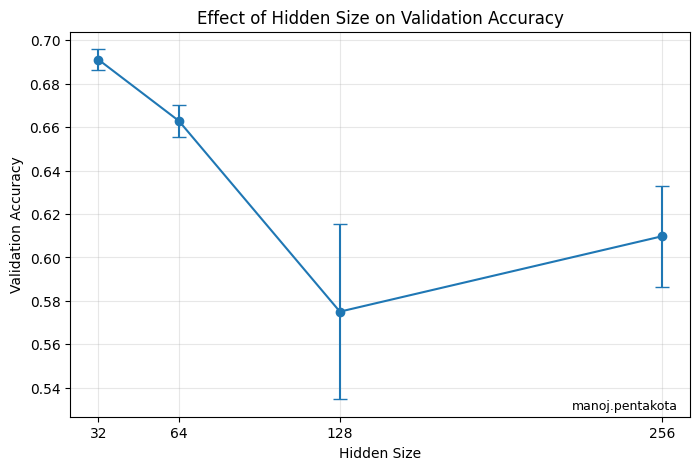

In [51]:
e2_val_plot_data = (
    e2_df.groupby("hidden_size")
    ["best_val_accuracy"]
    .agg(["mean", "std"])
)
plt.figure(figsize=(8, 5))
plt.errorbar(
    e2_val_plot_data.index,
    e2_val_plot_data["mean"],
    yerr=e2_val_plot_data["std"],
    marker="o",
    capsize=5
)
plt.xticks(HIDDEN_SIZES)
plt.xlabel("Hidden Size")
plt.ylabel("Validation Accuracy")
plt.title("Effect of Hidden Size on Validation Accuracy")
plt.grid(alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E2_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

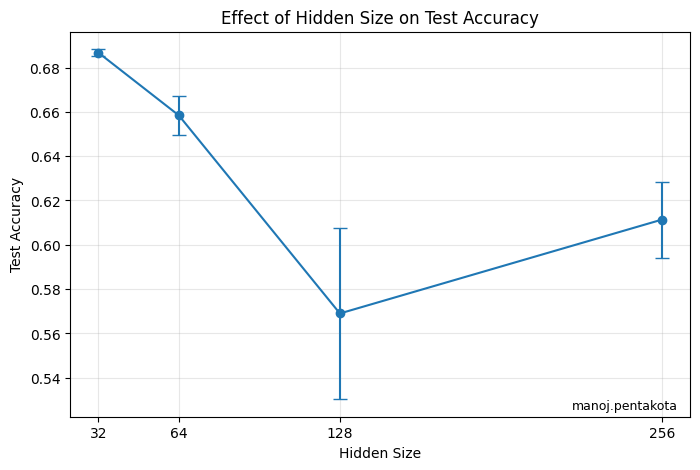

In [52]:
e2_test_plot_data = (
    e2_df.groupby("hidden_size")
    ["test_accuracy"]
    .agg(["mean", "std"])
)
plt.figure(figsize=(8, 5))
plt.errorbar(
    e2_test_plot_data.index,
    e2_test_plot_data["mean"],
    yerr=e2_test_plot_data["std"],
    marker="o",
    capsize=5
)
plt.xticks(HIDDEN_SIZES)
plt.xlabel("Hidden Size")
plt.ylabel("Test Accuracy")
plt.title("Effect of Hidden Size on Test Accuracy")
plt.grid(alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E2_test_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

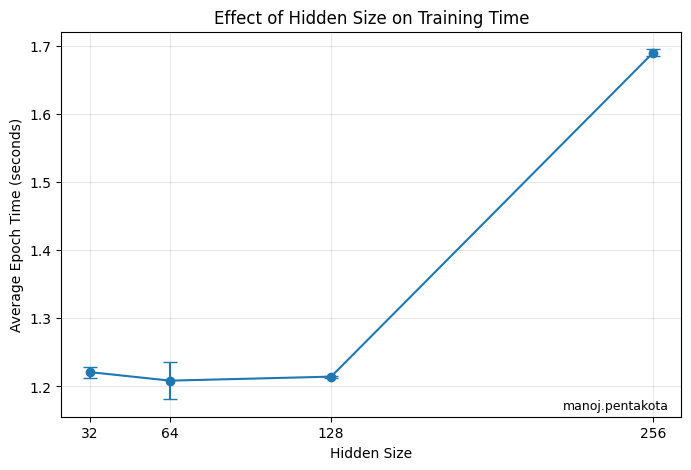

In [53]:
e2_time_plot_data = (
    e2_df.groupby("hidden_size")
    ["average_epoch_time_sec"]
    .agg(["mean", "std"])
)
plt.figure(figsize=(8, 5))
plt.errorbar(
    e2_time_plot_data.index,
    e2_time_plot_data["mean"],
    yerr=e2_time_plot_data["std"],
    marker="o",
    capsize=5
)
plt.xticks(HIDDEN_SIZES)
plt.xlabel("Hidden Size")
plt.ylabel("Average Epoch Time (seconds)")
plt.title("Effect of Hidden Size on Training Time")
plt.grid(alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E2_training_time.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

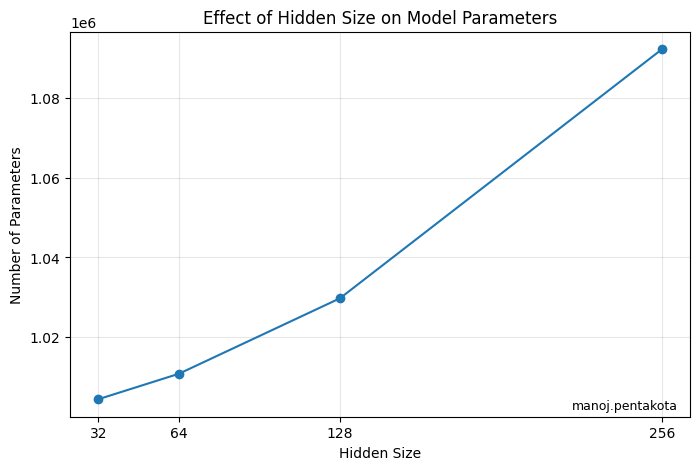

In [54]:
e2_param_data = (
    e2_df.groupby("hidden_size")
    ["parameters"]
    .mean()
)
plt.figure(figsize=(8, 5))
plt.plot(
    e2_param_data.index,
    e2_param_data.values,
    marker="o"
)
plt.xticks(HIDDEN_SIZES)
plt.xlabel("Hidden Size")
plt.ylabel("Number of Parameters")
plt.title("Effect of Hidden Size on Model Parameters")
plt.grid(alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E2_parameter_count.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [55]:
!pip install -q gensim

In [56]:
import gensim.downloader as api

glove_vectors = api.load("glove-wiki-gigaword-100")

print("Embedding dimension:", glove_vectors.vector_size)
print("Vocabulary size:", len(glove_vectors.key_to_index))

[==================================================] 100.0% 128.1/128.1MB downloaded
Embedding dimension: 100
Vocabulary size: 400000


In [57]:
def create_glove_embedding_matrix(vocab, embedding_dim=100):
    embedding_matrix = np.random.normal(
        loc=0.0,
        scale=0.1,
        size=(len(vocab), embedding_dim)
    ).astype(np.float32)
    found = 0
    missing = 0
    for word, idx in vocab.items():
        if word in ["<pad>", "<unk>"]:
            continue

        if word in glove_vectors:
            embedding_matrix[idx] = glove_vectors[word]
            found += 1
        else:
            missing += 1

    embedding_matrix[PAD_IDX] = np.zeros(embedding_dim)

    print("Words found in GloVe:", found)
    print("Words missing from GloVe:", missing)
    print("Vocabulary size:", len(vocab))
    print("Coverage:", found / (len(vocab) - 2))

    return torch.tensor(embedding_matrix, dtype=torch.float32)

In [58]:
GLOVE_EMBEDDING_MATRIX = create_glove_embedding_matrix(
    vocab,
    embedding_dim=100
)

print("Matrix shape:", GLOVE_EMBEDDING_MATRIX.shape)

Words found in GloVe: 9816
Words missing from GloVe: 184
Vocabulary size: 10002
Coverage: 0.9816
Matrix shape: torch.Size([10002, 100])


In [59]:
class IMDBSentimentRNNEmbeddingExperiment(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=100,
        hidden_size=64,
        padding_idx=0,
        embedding_type="random",
        pretrained_matrix=None
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )
        if embedding_type in ["glove_frozen", "glove_finetuned"]:
            if pretrained_matrix is None:
                raise ValueError(
                    "Pretrained matrix is required for GloVe models."
                )
            self.embedding.weight.data.copy_(pretrained_matrix)
            if embedding_type == "glove_frozen":
                self.embedding.weight.requires_grad = False
            elif embedding_type == "glove_finetuned":
                self.embedding.weight.requires_grad = True
        elif embedding_type == "random":
            self.embedding.weight.requires_grad = True
        else:
            raise ValueError(
                f"Invalid embedding_type: {embedding_type}"
            )
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=1,
            nonlinearity="tanh",
            batch_first=True,
            bias=True
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, token_ids):
        embeddings = self.embedding(token_ids)
        outputs, h_n = self.rnn(embeddings)
        h_final = h_n[-1]
        logits = self.fc(h_final).squeeze(-1)
        return logits

In [60]:
def run_embedding_experiment(embedding_type, seed):
    set_seed(seed)
    train_loader, val_loader, test_loader = create_loaders_for_length(
        max_length=150,
        batch_size=64
    )
    exp_model = IMDBSentimentRNNEmbeddingExperiment(
        vocab_size=len(vocab),
        embedding_dim=100,
        hidden_size=64,
        padding_idx=PAD_IDX,
        embedding_type=embedding_type,
        pretrained_matrix=GLOVE_EMBEDDING_MATRIX
    ).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        filter(
            lambda p: p.requires_grad,
            exp_model.parameters()
        ),
        lr=1e-3
    )
    config = {
        "experiment": "E3_embedding_initialization",
        "embedding_type": embedding_type,
        "sequence_length": 150,
        "vocab_size": len(vocab),
        "embedding_dim": 100,
        "hidden_size": 64,
        "batch_size": 64,
        "epochs": 10,
        "learning_rate": 1e-3,
        "optimizer": "Adam",
        "seed": seed
    }

    run = wandb.init(
        project="SMAI-A5-IMDB-RNN",
        name=f"E3_{embedding_type}_seed{seed}",
        config=config,
        tags=["E3", "embedding", embedding_type, f"seed-{seed}"],
        reinit=True
    )

    history_exp = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "epoch_time": []
    }

    best_val_acc = -1
    best_epoch = -1
    best_state = None
    total_start = time.time()
    for epoch in range(10):
        epoch_start = time.time()
        train_loss, train_acc = run_epoch(
            exp_model,
            train_loader,
            criterion,
            optimizer=optimizer,
            device=DEVICE
        )
        val_loss, val_acc = run_epoch(
            exp_model,
            val_loader,
            criterion,
            optimizer=None,
            device=DEVICE
        )
        epoch_time = time.time() - epoch_start
        history_exp["train_loss"].append(train_loss)
        history_exp["train_acc"].append(train_acc)
        history_exp["val_loss"].append(val_loss)
        history_exp["val_acc"].append(val_acc)
        history_exp["epoch_time"].append(epoch_time)

        wandb.log({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "epoch_time_sec": epoch_time
        })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = copy.deepcopy(exp_model.state_dict())

        print(
            f"{embedding_type} | Seed={seed} | "
            f"Epoch {epoch+1}/10 | "
            f"Train Acc={train_acc:.4f} | "
            f"Val Acc={val_acc:.4f} | "
            f"Time={epoch_time:.2f}s"
        )

    total_training_time = time.time() - total_start
    exp_model.load_state_dict(best_state)
    os.makedirs("/content/imdb_rnn_checkpoints", exist_ok=True)
    checkpoint_path = (
        f"/content/imdb_rnn_checkpoints/"
        f"E3_{embedding_type}_seed{seed}.pth"
    )
    torch.save({
        "model_state_dict": best_state,
        "best_val_accuracy": best_val_acc,
        "best_epoch": best_epoch,
        "config": config,
        "history": history_exp
    }, checkpoint_path)
    test_results = evaluate_model(
        exp_model,
        test_loader,
        device=DEVICE
    )
    avg_epoch_time = np.mean(history_exp["epoch_time"])
    total_params = sum(
        p.numel() for p in exp_model.parameters()
    )
    trainable_params = sum(
        p.numel() for p in exp_model.parameters()
        if p.requires_grad
    )
    results = {
    "embedding_type": embedding_type,
    "seed": seed,
    "best_epoch": best_epoch,
    "best_val_accuracy": best_val_acc,

    "test_accuracy": test_results["metrics"]["accuracy"],
    "test_precision": test_results["metrics"]["precision"],
    "test_recall": test_results["metrics"]["recall"],
    "test_f1": test_results["metrics"]["f1"],

    "average_epoch_time_sec": avg_epoch_time,
    "total_training_time_sec": total_training_time,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "checkpoint": checkpoint_path
}

    wandb.log({
    "best_val_accuracy": best_val_acc,
    "best_epoch": best_epoch,

    "test_accuracy": test_results["metrics"]["accuracy"],
    "test_precision": test_results["metrics"]["precision"],
    "test_recall": test_results["metrics"]["recall"],
    "test_f1": test_results["metrics"]["f1"],

    "average_epoch_time_sec": avg_epoch_time,
    "total_training_time_sec": total_training_time,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params
})

    wandb.finish()
    return results, history_exp, test_results

In [61]:
EMBEDDING_TYPES = [
    "random",
    "glove_frozen",
    "glove_finetuned"
]

EXPERIMENT_SEEDS = [42, 123]

e3_results = []
e3_histories = {}
for embedding_type in EMBEDDING_TYPES:
    for seed in EXPERIMENT_SEEDS:
        print("\n" + "=" * 80)
        print(
            f"Starting E3: Embedding={embedding_type}, Seed={seed}"
        )
        print("=" * 80)

        results, exp_history, test_results = (
            run_embedding_experiment(
                embedding_type=embedding_type,
                seed=seed
            )
        )
        e3_results.append(results)
        e3_histories[(embedding_type, seed)] = exp_history
        print("\nRun completed:")
        print(results)


Starting E3: Embedding=random, Seed=42


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


random | Seed=42 | Epoch 1/10 | Train Acc=0.5148 | Val Acc=0.5237 | Time=1.45s
random | Seed=42 | Epoch 2/10 | Train Acc=0.5678 | Val Acc=0.5371 | Time=1.19s
random | Seed=42 | Epoch 3/10 | Train Acc=0.6071 | Val Acc=0.5452 | Time=1.16s
random | Seed=42 | Epoch 4/10 | Train Acc=0.6377 | Val Acc=0.5422 | Time=1.16s
random | Seed=42 | Epoch 5/10 | Train Acc=0.6427 | Val Acc=0.6450 | Time=1.14s
random | Seed=42 | Epoch 6/10 | Train Acc=0.7247 | Val Acc=0.6576 | Time=1.15s
random | Seed=42 | Epoch 7/10 | Train Acc=0.6906 | Val Acc=0.5481 | Time=1.12s
random | Seed=42 | Epoch 8/10 | Train Acc=0.6512 | Val Acc=0.5293 | Time=1.34s
random | Seed=42 | Epoch 9/10 | Train Acc=0.6514 | Val Acc=0.5514 | Time=1.41s
random | Seed=42 | Epoch 10/10 | Train Acc=0.6872 | Val Acc=0.5664 | Time=1.44s


average_epoch_time_sec,▁
best_epoch,▁
best_val_accuracy,▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,█▂▂▂▁▂▁▆▇█
test_accuracy,▁
test_f1,▁
test_precision,▁
test_recall,▁
total_parameters,▁
+6,...



Run completed:
{'embedding_type': 'random', 'seed': 42, 'best_epoch': 6, 'best_val_accuracy': 0.6576116191500807, 'test_accuracy': 0.65204, 'test_precision': 0.7080459770114943, 'test_recall': 0.51744, 'test_f1': 0.5979200369771204, 'average_epoch_time_sec': np.float64(1.2573442697525024), 'total_training_time_sec': 12.595194339752197, 'total_parameters': 1010889, 'trainable_parameters': 1010889, 'checkpoint': '/content/imdb_rnn_checkpoints/E3_random_seed42.pth'}

Starting E3: Embedding=random, Seed=123


random | Seed=123 | Epoch 1/10 | Train Acc=0.5151 | Val Acc=0.5277 | Time=1.16s
random | Seed=123 | Epoch 2/10 | Train Acc=0.5850 | Val Acc=0.6243 | Time=1.25s
random | Seed=123 | Epoch 3/10 | Train Acc=0.5486 | Val Acc=0.5282 | Time=1.54s
random | Seed=123 | Epoch 4/10 | Train Acc=0.6096 | Val Acc=0.6027 | Time=1.14s
random | Seed=123 | Epoch 5/10 | Train Acc=0.6815 | Val Acc=0.6517 | Time=1.11s
random | Seed=123 | Epoch 6/10 | Train Acc=0.7010 | Val Acc=0.6681 | Time=1.12s
random | Seed=123 | Epoch 7/10 | Train Acc=0.7280 | Val Acc=0.6458 | Time=1.46s
random | Seed=123 | Epoch 8/10 | Train Acc=0.7474 | Val Acc=0.6127 | Time=1.42s
random | Seed=123 | Epoch 9/10 | Train Acc=0.7728 | Val Acc=0.6608 | Time=1.28s
random | Seed=123 | Epoch 10/10 | Train Acc=0.7816 | Val Acc=0.5401 | Time=1.11s


... (10 outputs left out)


Run completed:
{'embedding_type': 'glove_finetuned', 'seed': 42, 'best_epoch': 7, 'best_val_accuracy': 0.7248520710059172, 'test_accuracy': 0.71396, 'test_precision': 0.7126500755347062, 'test_recall': 0.71704, 'test_f1': 0.7148382980420306, 'average_epoch_time_sec': np.float64(1.235613799095154), 'total_training_time_sec': 12.373122692108154, 'total_parameters': 1010889, 'trainable_parameters': 1010889, 'checkpoint': '/content/imdb_rnn_checkpoints/E3_glove_finetuned_seed42.pth'}

Starting E3: Embedding=glove_finetuned, Seed=123


glove_finetuned | Seed=123 | Epoch 1/10 | Train Acc=0.5603 | Val Acc=0.5414 | Time=1.15s
glove_finetuned | Seed=123 | Epoch 2/10 | Train Acc=0.6032 | Val Acc=0.6323 | Time=1.15s
glove_finetuned | Seed=123 | Epoch 3/10 | Train Acc=0.6624 | Val Acc=0.5382 | Time=1.16s
glove_finetuned | Seed=123 | Epoch 4/10 | Train Acc=0.6968 | Val Acc=0.6713 | Time=1.17s
glove_finetuned | Seed=123 | Epoch 5/10 | Train Acc=0.6857 | Val Acc=0.5995 | Time=1.20s
glove_finetuned | Seed=123 | Epoch 6/10 | Train Acc=0.7445 | Val Acc=0.6727 | Time=1.42s
glove_finetuned | Seed=123 | Epoch 7/10 | Train Acc=0.7234 | Val Acc=0.5196 | Time=1.43s
glove_finetuned | Seed=123 | Epoch 8/10 | Train Acc=0.7645 | Val Acc=0.5446 | Time=1.37s
glove_finetuned | Seed=123 | Epoch 9/10 | Train Acc=0.8051 | Val Acc=0.5958 | Time=1.16s
glove_finetuned | Seed=123 | Epoch 10/10 | Train Acc=0.8445 | Val Acc=0.6662 | Time=1.18s


average_epoch_time_sec,▁
best_epoch,▁
best_val_accuracy,▁
epoch,▁▂▃▃▄▅▆▆▇█
epoch_time_sec,▁▁▁▂▂██▇▁▂
test_accuracy,▁
test_f1,▁
test_precision,▁
test_recall,▁
total_parameters,▁
+6,...



Run completed:
{'embedding_type': 'glove_finetuned', 'seed': 123, 'best_epoch': 6, 'best_val_accuracy': 0.6726734803657881, 'test_accuracy': 0.6786, 'test_precision': 0.6615529343657284, 'test_recall': 0.73136, 'test_f1': 0.6947072457160226, 'average_epoch_time_sec': np.float64(1.2393997192382813), 'total_training_time_sec': 12.413584232330322, 'total_parameters': 1010889, 'trainable_parameters': 1010889, 'checkpoint': '/content/imdb_rnn_checkpoints/E3_glove_finetuned_seed123.pth'}


In [62]:
e3_df = pd.DataFrame(e3_results)
e3_summary = (
    e3_df.groupby("embedding_type")
    .agg({
        "best_val_accuracy": ["mean", "std"],
        "test_accuracy": ["mean", "std"],
        "test_f1": ["mean", "std"],
        "average_epoch_time_sec": ["mean", "std"],
        "total_training_time_sec": "mean",
        "total_parameters": "mean",
        "trainable_parameters": "mean"
    })
)
display(e3_df)
display(e3_summary)

,embedding_type,seed,best_epoch,best_val_accuracy,test_accuracy,test_precision,test_recall,test_f1,average_epoch_time_sec,total_training_time_sec,total_parameters,trainable_parameters,checkpoint
0,random,42,6,0.657612,0.65204,0.708046,0.51744,0.597920,1.257344,12.595194,1010889,1010889,/content/imdb_rnn_checkpoints/E3_random_seed42...
1,random,123,6,0.668101,0.66472,0.666370,0.65976,0.663049,1.258159,12.609686,1010889,1010889,/content/imdb_rnn_checkpoints/E3_random_seed12...
2,glove_frozen,42,3,0.622109,0.63544,0.606091,0.77376,0.679739,1.149220,11.510459,1010889,10689,/content/imdb_rnn_checkpoints/E3_glove_frozen_...
3,glove_frozen,123,5,0.606778,0.59876,0.601580,0.58488,0.593112,1.124767,11.267852,1010889,10689,/content/imdb_rnn_checkpoints/E3_glove_frozen_...
4,glove_finetuned,42,7,0.724852,0.71396,0.712650,0.71704,0.714838,1.235614,12.373123,1010889,1010889,/content/imdb_rnn_checkpoints/E3_glove_finetun...
5,glove_finetuned,123,6,0.672673,0.67860,0.661553,0.73136,0.694707,1.239400,12.413584,1010889,1010889,/content/imdb_rnn_checkpoints/E3_glove_finetun...


best_val_accuracy           test_accuracy             test_f1  \
                             mean       std          mean       std      mean   
embedding_type                                                                  
glove_finetuned          0.698763  0.036896       0.69628  0.025003  0.704773   
glove_frozen             0.614443  0.010841       0.61710  0.025937  0.636425   
random                   0.662856  0.007417       0.65838  0.008966  0.630484   

                          average_epoch_time_sec            \
                      std                   mean       std   
embedding_type                                               
glove_finetuned  0.014235               1.237507  0.002677   
glove_frozen     0.061254               1.136994  0.017291   
random           0.046053               1.257752  0.000576   

                total_training_time_sec total_parameters trainable_parameters  
                                   mean             mean                 mean  
embedding_type                                                                 
glove_finetuned               12.393353        1010889.0            1010889.0  
glove_frozen                  11.389155        1010889.0              10689.0  
random                        12.602440        1010889.0            1010889.0

In [63]:
e3_df.to_csv(
    "/content/E3_embedding_results.csv",
    index=False
)
e3_summary.to_csv(
    "/content/E3_embedding_summary.csv"
)

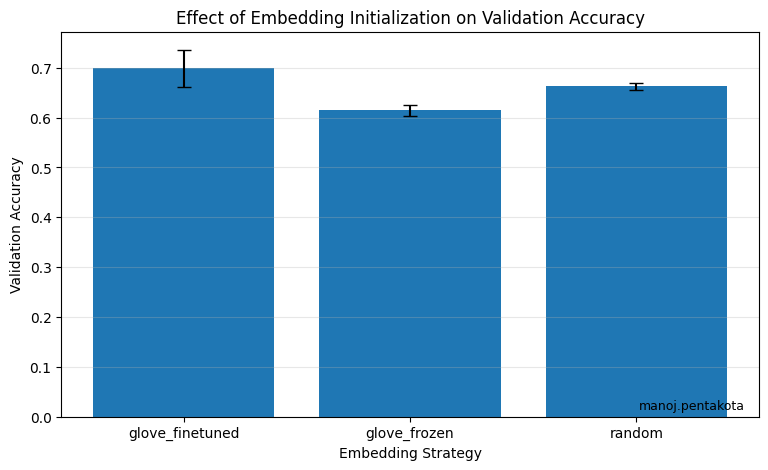

In [64]:
e3_val_data = (
    e3_df.groupby("embedding_type")
    ["best_val_accuracy"]
    .agg(["mean", "std"])
)
plt.figure(figsize=(9, 5))
plt.bar(
    e3_val_data.index,
    e3_val_data["mean"],
    yerr=e3_val_data["std"],
    capsize=5
)
plt.ylabel("Validation Accuracy")
plt.xlabel("Embedding Strategy")
plt.title("Effect of Embedding Initialization on Validation Accuracy")
plt.grid(axis="y", alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E3_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

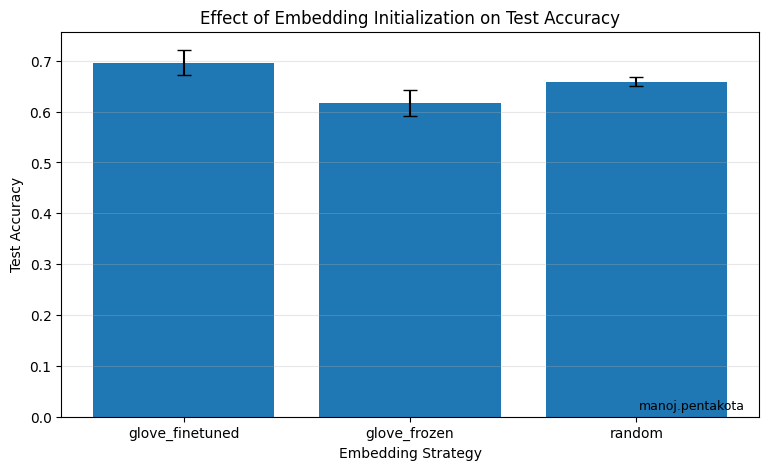

In [65]:
e3_test_data = (
    e3_df.groupby("embedding_type")
    ["test_accuracy"]
    .agg(["mean", "std"])
)
plt.figure(figsize=(9, 5))
plt.bar(
    e3_test_data.index,
    e3_test_data["mean"],
    yerr=e3_test_data["std"],
    capsize=5
)
plt.ylabel("Test Accuracy")
plt.xlabel("Embedding Strategy")
plt.title("Effect of Embedding Initialization on Test Accuracy")
plt.grid(axis="y", alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E3_test_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

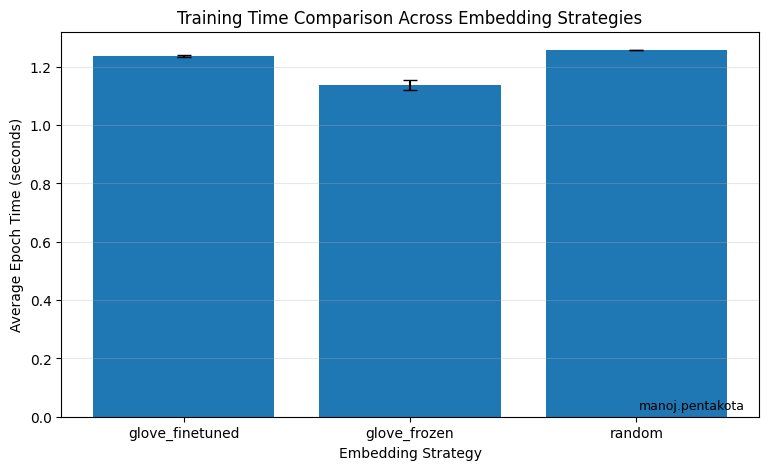

In [66]:
e3_time_data = (
    e3_df.groupby("embedding_type")
    ["average_epoch_time_sec"]
    .agg(["mean", "std"])
)
plt.figure(figsize=(9, 5))
plt.bar(
    e3_time_data.index,
    e3_time_data["mean"],
    yerr=e3_time_data["std"],
    capsize=5
)
plt.ylabel("Average Epoch Time (seconds)")
plt.xlabel("Embedding Strategy")
plt.title("Training Time Comparison Across Embedding Strategies")
plt.grid(axis="y", alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E3_training_time.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

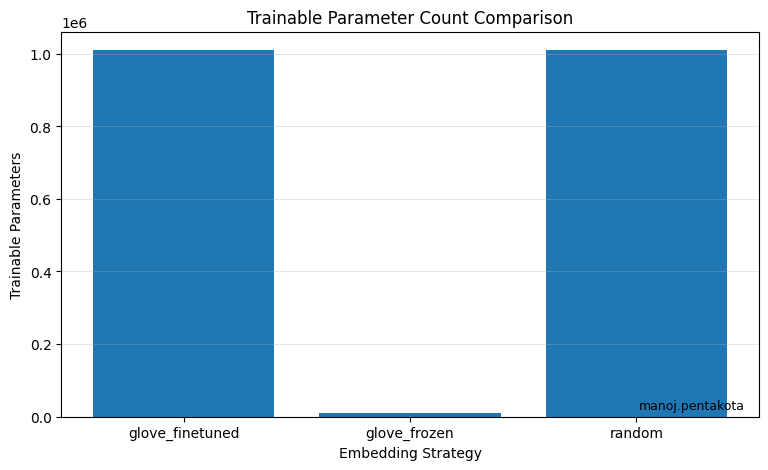

In [67]:
e3_param_data = (
    e3_df.groupby("embedding_type")
    ["trainable_parameters"]
    .mean()
)
plt.figure(figsize=(9, 5))
plt.bar(e3_param_data.index,e3_param_data.values)
plt.ylabel("Trainable Parameters")
plt.xlabel("Embedding Strategy")
plt.title("Trainable Parameter Count Comparison")
plt.grid(axis="y", alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.savefig(
    "/content/E3_trainable_parameters.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [68]:
e3_report = (
    e3_df.groupby("embedding_type")
    .agg(
        val_accuracy_mean=("best_val_accuracy", "mean"),
        val_accuracy_std=("best_val_accuracy", "std"),

        test_accuracy_mean=("test_accuracy", "mean"),
        test_accuracy_std=("test_accuracy", "std"),

        parameters=("total_parameters", "mean"),
        trainable_parameters=("trainable_parameters", "mean"),

        training_time_mean=("total_training_time_sec", "mean"),
        epoch_time_mean=("average_epoch_time_sec", "mean")
    )
    .reset_index()
)

display(e3_report.round(4))

,embedding_type,val_accuracy_mean,val_accuracy_std,test_accuracy_mean,test_accuracy_std,parameters,trainable_parameters,training_time_mean,epoch_time_mean
0,glove_finetuned,0.6988,0.0369,0.6963,0.0250,1010889.0,1010889.0,12.3934,1.2375
1,glove_frozen,0.6144,0.0108,0.6171,0.0259,1010889.0,10689.0,11.3892,1.1370
2,random,0.6629,0.0074,0.6584,0.0090,1010889.0,1010889.0,12.6024,1.2578


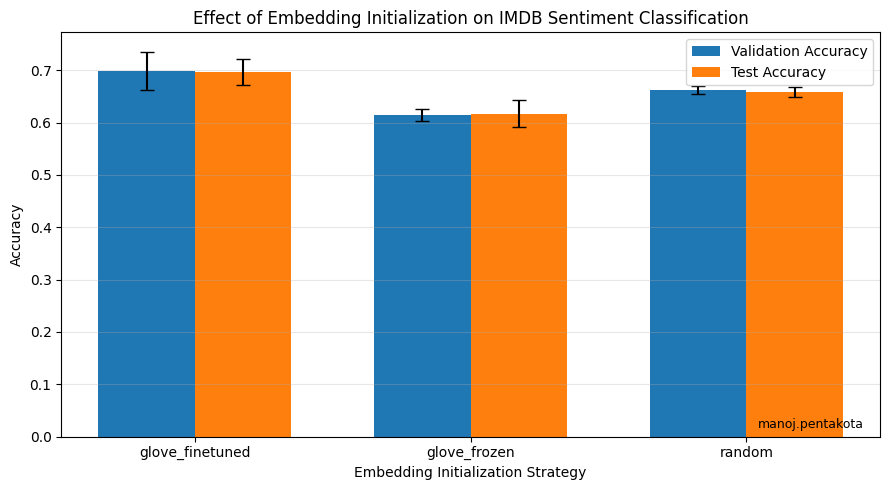

In [69]:
plot_df = (
    e3_df.groupby("embedding_type")
    .agg(
        val_mean=("best_val_accuracy", "mean"),
        val_std=("best_val_accuracy", "std"),
        test_mean=("test_accuracy", "mean"),
        test_std=("test_accuracy", "std")
    )
)
x = np.arange(len(plot_df))
width = 0.35
plt.figure(figsize=(9, 5))
plt.bar(
    x - width / 2,
    plot_df["val_mean"],
    width,
    yerr=plot_df["val_std"],
    capsize=5,
    label="Validation Accuracy"
)
plt.bar(
    x + width / 2,
    plot_df["test_mean"],
    width,
    yerr=plot_df["test_std"],
    capsize=5,
    label="Test Accuracy"
)
plt.xticks(x, plot_df.index)
plt.ylabel("Accuracy")
plt.xlabel("Embedding Initialization Strategy")
plt.title("Effect of Embedding Initialization on IMDB Sentiment Classification")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.annotate(
    "manoj.pentakota",
    xy=(0.98, 0.02),
    xycoords="axes fraction",
    ha="right",
    fontsize=9
)
plt.tight_layout()
plt.savefig(
    "/content/E3_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Pretrained GloVe embeddings are often expected to improve sentiment classification compared with randomly initialised embeddings because they provide semantic representations learned from a large external corpus. Fine-tuning those embeddings is often expected to outperform freezing them, because the representations can adapt to sentiment-specific patterns in the IMDB training data. This experiment tests those expectations directly. If the random baseline remains competitive, plausible explanations include the limited 10-epoch training budget, the mismatch between the 100-dimensional GloVe vocabulary and this dataset's tokenisation, and the fact that the RNN can learn useful task-specific embeddings from 21k labelled reviews.


In [70]:
def copy_builtin_weights_to_scratch(builtin_model, scratch_model):
    with torch.no_grad():
        scratch_model.embedding.weight.copy_(builtin_model.embedding.weight)
        scratch_model.rnn.cell.weight_ih.copy_(builtin_model.rnn.weight_ih_l0)
        scratch_model.rnn.cell.weight_hh.copy_(builtin_model.rnn.weight_hh_l0)
        scratch_model.rnn.cell.bias_ih.copy_(builtin_model.rnn.bias_ih_l0)
        scratch_model.rnn.cell.bias_hh.copy_(builtin_model.rnn.bias_hh_l0)
        scratch_model.fc.weight.copy_(builtin_model.fc.weight)
        scratch_model.fc.bias.copy_(builtin_model.fc.bias)

In [71]:
class IMDBSentimentRNNGradient(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=100,
        hidden_size=64,
        padding_idx=0
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=padding_idx
        )
        self.rnn = RNNScratch(
            input_size=embedding_dim,
            hidden_size=hidden_size
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, token_ids, retain_hidden_grads=False):
        embeddings = self.embedding(token_ids)
        outputs, h_final = self.rnn(
            embeddings,
            retain_hidden_grads=retain_hidden_grads
        )
        logits = self.fc(h_final).squeeze(-1)
        return logits

In [72]:
def load_builtin_checkpoint(sequence_length, seed=42):
    checkpoint_path = (
        f"/content/imdb_rnn_checkpoints/"
        f"E1_length{sequence_length}_seed{seed}.pth"
    )
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )
    builtin_model = IMDBSentimentRNN(
        vocab_size=len(vocab),
        embedding_dim=100,
        hidden_size=64,
        padding_idx=PAD_IDX
    ).to(DEVICE)
    builtin_model.load_state_dict(checkpoint["model_state_dict"])
    builtin_model.eval()
    return builtin_model

In [73]:
def calculate_hidden_gradient_norms(
    model,
    loader,
    device=DEVICE
):
    model.eval()
    model.zero_grad(set_to_none=True)
    token_ids, lengths, labels = next(iter(loader))
    token_ids = token_ids.to(device)
    labels = labels.to(device)
    logits = model(
        token_ids,
        retain_hidden_grads=True
    )
    criterion = nn.BCEWithLogitsLoss()
    loss = criterion(logits, labels)
    loss.backward()
    hidden_grads = model.rnn.hidden_grads
    gradient_norms = []
    for grad in hidden_grads:
        norm_per_sample = torch.norm(
            grad,
            p=2,
            dim=1
        )
        mean_norm = norm_per_sample.mean().item()
        gradient_norms.append(mean_norm)
    return gradient_norms, loss.item()

In [74]:
class RNNScratch(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.cell = RNNCellScratch(
            input_size,
            hidden_size
        )
        self.hidden_grads = []

    def forward(
        self,
        x,
        retain_hidden_grads=False
    ):
        batch_size, sequence_length, input_size = x.shape
        h_t = torch.zeros(
            batch_size,
            self.hidden_size,
            device=x.device,
            dtype=x.dtype
        )
        outputs = []
        hidden_states = []
        self.hidden_grads = []
        for t in range(sequence_length):
            x_t = x[:, t, :]
            h_t = self.cell(x_t, h_t)
            if retain_hidden_grads:
                h_t.retain_grad()
            outputs.append(h_t)
            hidden_states.append(h_t)
        output_sequence = torch.stack(outputs, dim=1)
        h_final = h_t
        if retain_hidden_grads:
            self.hidden_grads = hidden_states
        return output_sequence, h_final

In [75]:
gradient_results = {}
for seq_length in [50, 400]:
    train_loader, val_loader, test_loader = create_loaders_for_length(
        max_length=seq_length,
        batch_size=64
    )
    set_seed(SEED)
    untrained_model = IMDBSentimentRNNGradient(
        vocab_size=len(vocab),
        embedding_dim=100,
        hidden_size=64,
        padding_idx=PAD_IDX
    ).to(DEVICE)
    untrained_norms, untrained_loss = (
        calculate_hidden_gradient_norms(
            untrained_model,
            val_loader,
            device=DEVICE
        )
    )
    trained_builtin = load_builtin_checkpoint(
        sequence_length=seq_length,
        seed=SEED
    )
    trained_scratch = IMDBSentimentRNNGradient(
        vocab_size=len(vocab),
        embedding_dim=100,
        hidden_size=64,
        padding_idx=PAD_IDX
    ).to(DEVICE)
    copy_builtin_weights_to_scratch(
        trained_builtin,
        trained_scratch
    )
    trained_norms, trained_loss = (
        calculate_hidden_gradient_norms(
            trained_scratch,
            val_loader,
            device=DEVICE
        )
    )
    gradient_results[seq_length] = {
        "untrained": untrained_norms,
        "trained": trained_norms,
        "untrained_loss": untrained_loss,
        "trained_loss": trained_loss
    }
    print(f"\nSequence length: {seq_length}")
    print(f"Untrained loss: {untrained_loss:.4f}")
    print(f"Trained loss:   {trained_loss:.4f}")


Sequence length: 50
Untrained loss: 0.7205
Trained loss:   0.6907

Sequence length: 400
Untrained loss: 0.6880
Trained loss:   0.6582


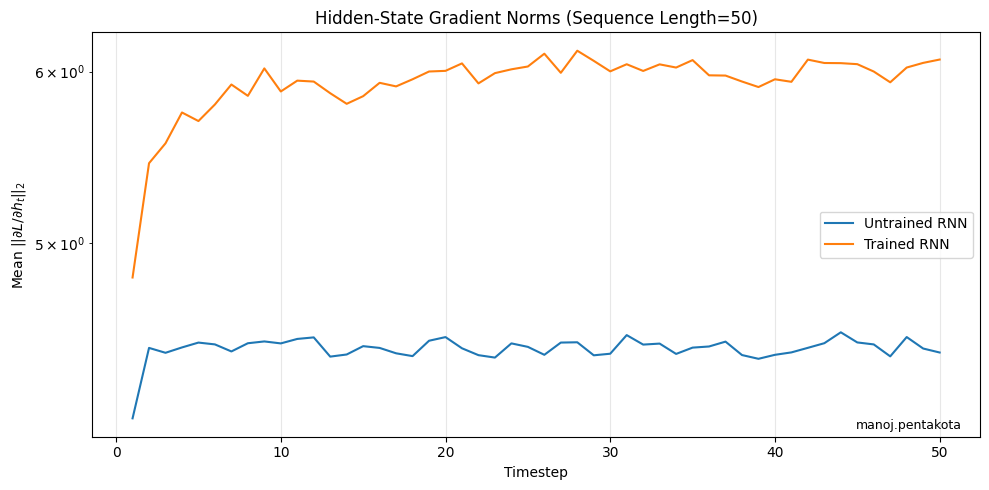

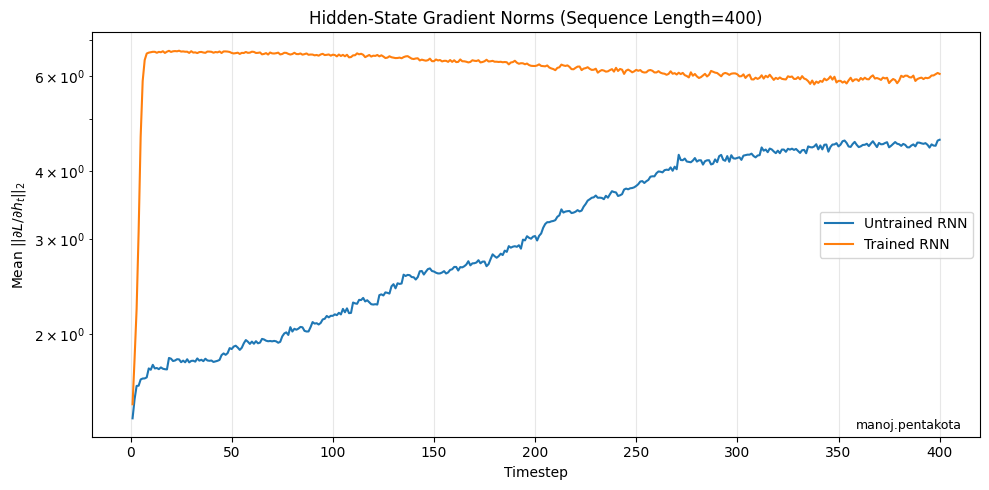

In [76]:
for seq_length in [50, 400]:
    untrained_norms = gradient_results[seq_length]["untrained"]
    trained_norms = gradient_results[seq_length]["trained"]
    timesteps = np.arange(1, seq_length + 1)
    plt.figure(figsize=(10, 5))
    plt.plot(
        timesteps,
        untrained_norms,
        label="Untrained RNN"
    )
    plt.plot(
        timesteps,
        trained_norms,
        label="Trained RNN"
    )
    plt.yscale("log")
    plt.xlabel("Timestep")
    plt.ylabel(r"Mean $||\partial L/\partial h_t||_2$")
    plt.title(f"Hidden-State Gradient Norms (Sequence Length={seq_length})")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.annotate(
        "manoj.pentakota",
        xy=(0.98, 0.02),
        xycoords="axes fraction",
        ha="right",
        fontsize=9
    )
    plt.tight_layout()
    plt.savefig(
        f"/content/gradient_analysis_L{seq_length}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

In [77]:
candidate_rows = []

candidate_rows.append({
    "source": "main",
    "sequence_length": 150,
    "hidden_size": 64,
    "seed": main_results["seed"],
    "best_val_accuracy": main_results["best_validation_accuracy"],
    "test_accuracy": main_results["test_accuracy"],
    "checkpoint": main_results["checkpoint"],
})

for _, row in e1_df.iterrows():
    candidate_rows.append({
        "source": "E1",
        "sequence_length": int(row["sequence_length"]),
        "hidden_size": 64,
        "seed": int(row["seed"]),
        "best_val_accuracy": float(row["best_val_accuracy"]),
        "test_accuracy": float(row["test_accuracy"]),
        "checkpoint": row["checkpoint"],
    })

for _, row in e2_df.iterrows():
    candidate_rows.append({
        "source": "E2",
        "sequence_length": 150,
        "hidden_size": int(row["hidden_size"]),
        "seed": int(row["seed"]),
        "best_val_accuracy": float(row["best_val_accuracy"]),
        "test_accuracy": float(row["test_accuracy"]),
        "checkpoint": row["checkpoint"],
    })

for _, row in e3_df.iterrows():
    candidate_rows.append({
        "source": "E3",
        "sequence_length": 150,
        "hidden_size": 64,
        "seed": int(row["seed"]),
        "best_val_accuracy": float(row["best_val_accuracy"]),
        "test_accuracy": float(row["test_accuracy"]),
        "checkpoint": row["checkpoint"],
    })

final_candidates_df = (
    pd.DataFrame(candidate_rows)
    .sort_values("best_val_accuracy", ascending=False)
    .reset_index(drop=True)
)
display(final_candidates_df)

FINAL_ROW = final_candidates_df.iloc[0]
FINAL_SOURCE = FINAL_ROW["source"]
FINAL_SEQUENCE_LENGTH = int(FINAL_ROW["sequence_length"])
FINAL_HIDDEN_SIZE = int(FINAL_ROW["hidden_size"])
FINAL_CHECKPOINT = FINAL_ROW["checkpoint"]

print("Selected by validation accuracy:")
print(FINAL_ROW.to_dict())

# The checkpoint state dict has the same keys for all four model families
# (embedding, RNN, linear), so the standard classifier can load E1/E2/E3.
FINAL_MODEL = IMDBSentimentRNN(
    vocab_size=len(vocab),
    embedding_dim=100,
    hidden_size=FINAL_HIDDEN_SIZE,
    padding_idx=PAD_IDX
).to(DEVICE)

final_checkpoint = torch.load(
    FINAL_CHECKPOINT,
    map_location=DEVICE,
    weights_only=True
)
FINAL_MODEL.load_state_dict(final_checkpoint["model_state_dict"])
FINAL_MODEL.eval()

_, _, final_test_loader = create_loaders_for_length(
    max_length=FINAL_SEQUENCE_LENGTH,
    batch_size=64
)
FINAL_TEST_RESULTS = evaluate_model(
    FINAL_MODEL,
    final_test_loader,
    device=DEVICE
)

final_metrics = FINAL_TEST_RESULTS["metrics"]
final_model_results = pd.DataFrame([{
    "source": FINAL_SOURCE,
    "sequence_length": FINAL_SEQUENCE_LENGTH,
    "hidden_size": FINAL_HIDDEN_SIZE,
    "seed": int(FINAL_ROW["seed"]),
    "checkpoint": FINAL_CHECKPOINT,
    "best_validation_accuracy": float(FINAL_ROW["best_val_accuracy"]),
    "test_accuracy": final_metrics["accuracy"],
    "test_precision": final_metrics["precision"],
    "test_recall": final_metrics["recall"],
    "test_f1": final_metrics["f1"],
}])

display(final_model_results.round(4))
final_model_results.to_csv(
    "/content/Q2_final_model_results.csv",
    index=False
)

print("\nFinal test confusion matrix:")
print(final_metrics["confusion_matrix"])


,source,sequence_length,hidden_size,seed,best_val_accuracy,test_accuracy,checkpoint
0,E1,400,64,123,0.748252,0.74656,/content/imdb_rnn_checkpoints/E1_length400_see...
1,E1,400,64,42,0.735611,0.73128,/content/imdb_rnn_checkpoints/E1_length400_see...
2,E3,150,64,42,0.724852,0.71396,/content/imdb_rnn_checkpoints/E3_glove_finetun...
3,E2,150,32,123,0.694459,0.68564,/content/imdb_rnn_checkpoints/E2_hidden32_seed...
4,E2,150,32,42,0.687735,0.68780,/content/imdb_rnn_checkpoints/E2_hidden32_seed...
5,main,150,64,42,0.676708,0.67020,/content/imdb_rnn_checkpoints/best_main_rnn.pth
6,E1,50,64,123,0.674825,0.66264,/content/imdb_rnn_checkpoints/E1_length50_seed...
7,E3,150,64,123,0.672673,0.67860,/content/imdb_rnn_checkpoints/E3_glove_finetun...
8,E1,150,64,123,0.668101,0.66472,/content/imdb_rnn_checkpoints/E1_length150_see...
9,E2,150,64,123,0.668101,0.66472,/content/imdb_rnn_checkpoints/E2_hidden64_seed...


Selected by validation accuracy:
{'source': 'E1', 'sequence_length': 400, 'hidden_size': 64, 'seed': 123, 'best_val_accuracy': 0.7482517482517482, 'test_accuracy': 0.74656, 'checkpoint': '/content/imdb_rnn_checkpoints/E1_length400_seed123.pth'}


,source,sequence_length,hidden_size,seed,checkpoint,best_validation_accuracy,test_accuracy,test_precision,test_recall,test_f1
0,E1,400,64,123,/content/imdb_rnn_checkpoints/E1_length400_see...,0.7483,0.7466,0.6997,0.8638,0.7731



Final test confusion matrix:
[[ 7867  4633]
 [ 1703 10797]]


In [78]:
test_labels = FINAL_TEST_RESULTS["labels"]
test_predictions = FINAL_TEST_RESULTS["predictions"]
test_probabilities = FINAL_TEST_RESULTS["probabilities"]

misclassified_indices = np.where(
    test_labels != test_predictions
)[0]
error_rows = []

for idx in misclassified_indices:
    review_text = test_df.iloc[idx]["text"]
    true_label = int(test_labels[idx])
    predicted_label = int(test_predictions[idx])
    positive_probability = float(test_probabilities[idx])
    predicted_confidence = (
        positive_probability
        if predicted_label == 1
        else 1 - positive_probability
    )
    token_count = len(preprocess_text(review_text))
    error_rows.append({
        "test_index": idx,
        "true_label": true_label,
        "predicted_label": predicted_label,
        "positive_probability": positive_probability,
        "predicted_confidence": predicted_confidence,
        "error_type": (
            "False Positive"
            if true_label == 0 and predicted_label == 1
            else "False Negative"
        ),
        "token_count": token_count,
        "truncated": token_count > 150,
        "review": review_text
    })

error_df = pd.DataFrame(error_rows)
# Use a mix of false negatives and false positives instead of allowing
# confidence sorting to select only one error type.
false_negatives = (
    error_df[error_df["error_type"] == "False Negative"]
    .sort_values("predicted_confidence", ascending=False)
)
false_positives = (
    error_df[error_df["error_type"] == "False Positive"]
    .sort_values("predicted_confidence", ascending=False)
)

selected_errors = pd.concat([
    false_negatives.head(3),
    false_positives.head(2),
])
if len(selected_errors) < 5:
    remaining = (
        error_df.drop(index=selected_errors.index)
        .sort_values("predicted_confidence", ascending=False)
        .head(5 - len(selected_errors))
    )
    selected_errors = pd.concat([selected_errors, remaining])

top5_errors = (
    selected_errors
    .drop_duplicates("test_index")
    .head(5)
    .reset_index(drop=True)
)

print("Total misclassified reviews:", len(error_df))
print("\nSelected five errors:")
display(
    top5_errors[
        [
            "test_index",
            "true_label",
            "predicted_label",
            "positive_probability",
            "error_type",
            "token_count",
            "truncated"
        ]
    ]
)

Total misclassified reviews: 6336

Selected five errors:


,test_index,true_label,predicted_label,positive_probability,error_type,token_count,truncated
0,23601,1,0,0.064669,False Negative,465,True
1,24658,1,0,0.071687,False Negative,106,False
2,19467,1,0,0.076294,False Negative,475,True
3,9345,0,1,0.957662,False Positive,147,False
4,1982,0,1,0.955095,False Positive,174,True


In [79]:
for i, row in top5_errors.iterrows():
    true_sentiment = ("Positive" if row["true_label"] == 1 else "Negative")
    predicted_sentiment = (
        "Positive" if row["predicted_label"] == 1 else "Negative"
    )
    print("=" * 100)
    print(f"Review {i+1}")
    print("=" * 100)

    print(f"True sentiment: {true_sentiment}")
    print(f"Predicted sentiment: {predicted_sentiment}")
    print(f"Error type: {row['error_type']}")
    print(f"Positive probability: {row['positive_probability']:.4f}")
    print(f"Token count: {row['token_count']}")
    print(f"Truncated at 150 tokens: {row['truncated']}")

    print("\nReview text:\n")
    print(row["review"])

    print("\n")

Review 1
True sentiment: Positive
Predicted sentiment: Negative
Error type: False Negative
Positive probability: 0.0647
Token count: 465
Truncated at 150 tokens: True

Review text:

039: Anna Christie (1930) - released 2/21/1930; viewed 3/10/06 <br /><br />On October 24, 1929: Black Thursday, the stock market crashes. Now the country and indeed the world will look to Hollywood for escape from the worldwide Great Depression.<br /><br />BIRTHS: Anne Frank, June Carter, Yasser Arafat, Bob Newhart, Barbara Walters, Doris Roberts, Ed Asner, Dick Clark, Roy E. Disney, Gene Hackman.<br /><br />DOUG: At long last, our Odyssey resumes in earnest with Greta Garbo's first sound film, a simple character study called Anna Christie. An excellent performance from Ms. Garbo, who showed right off the bat that her talents could carry over from the silent era (I wanted to see some of her silent work, but Netflix doesn't seem to be stocking them. How odd). One thing I noticed over and over was the way the

In [80]:
top5_errors.to_csv(
    "/content/Q2_error_analysis_5_reviews.csv",
    index=False
)

In [81]:
error_df.to_csv(
    "/content/Q2_all_misclassified_reviews.csv",
    index=False
)

In [82]:
import copy
import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import wandb
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

CLIP_MAX_NORM = 1.0
CLIP_EPOCHS = 10
CLIP_LR = 1e-3
CLIP_BATCH_SIZE = 64
CLIP_SEEDS = [42, 123]

def make_clipping_loaders(seed):
    generator = torch.Generator()
    generator.manual_seed(seed)
    train_dl = DataLoader(
        train_loader.dataset,
        batch_size=CLIP_BATCH_SIZE,
        shuffle=True,
        generator=generator
    )
    val_dl = DataLoader(
        val_loader.dataset,
        batch_size=CLIP_BATCH_SIZE,
        shuffle=False
    )
    test_dl = DataLoader(
        test_loader.dataset,
        batch_size=CLIP_BATCH_SIZE,
        shuffle=False
    )
    return train_dl, val_dl, test_dl

def make_fresh_default_model():
    fresh_model = copy.deepcopy(model)
    for module in fresh_model.modules():
        if module is not fresh_model and hasattr(module, "reset_parameters"):
            module.reset_parameters()
    return fresh_model.to(DEVICE)

initial_states = {}

for seed in CLIP_SEEDS:
    set_seed(seed)
    fresh_model = make_fresh_default_model()
    initial_states[seed] = copy.deepcopy(fresh_model.state_dict())
    del fresh_model

print("Prepared identical initial weights for both clipping conditions")

Prepared identical initial weights for both clipping conditions


In [83]:
def get_total_gradient_norm(parameters):
    """calculate the global L2 norm of all parameter gradients"""
    grad_norms = [
        p.grad.detach().norm(2)
        for p in parameters
        if p.grad is not None
    ]
    if not grad_norms:
        return 0.0
    return torch.stack(grad_norms).norm(2).item()

def evaluate_for_clipping(model_to_eval, loader, criterion):
    model_to_eval.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    with torch.no_grad():
        for batch in loader:
            input_ids, lengths, labels = batch
            input_ids = input_ids.to(DEVICE)
            labels = labels.float().to(DEVICE).view(-1)
            logits = model_to_eval(input_ids).view(-1)
            loss = criterion(logits, labels)
            predictions = (torch.sigmoid(logits) >= 0.5).long()
            total_loss += loss.item() * labels.size(0)
            total_correct += (predictions == labels.long()).sum().item()
            total_samples += labels.size(0)
    return {
        "loss": total_loss / total_samples,
        "accuracy": total_correct / total_samples
    }

def train_clipping_condition(seed, use_clipping, initial_state):
    condition = "with_clipping" if use_clipping else "without_clipping"
    set_seed(seed)
    train_dl, val_dl, test_dl = make_clipping_loaders(seed)
    model_to_train = make_fresh_default_model()
    model_to_train.load_state_dict(copy.deepcopy(initial_state))
    optimizer = torch.optim.Adam(model_to_train.parameters(), lr=CLIP_LR)
    criterion = nn.BCEWithLogitsLoss()
    run = wandb.init(
        project="SMAI-A5-IMDB-RNN",
        name=f"gradient_clipping_{condition}_seed{seed}",
        config={
            "experiment": "gradient_clipping",
            "condition": condition,
            "seed": seed,
            "sequence_length": 150,
            "embedding_dim": 100,
            "hidden_size": 64,
            "batch_size": CLIP_BATCH_SIZE,
            "epochs": CLIP_EPOCHS,
            "optimizer": "Adam",
            "learning_rate": CLIP_LR,
            "max_norm": CLIP_MAX_NORM if use_clipping else None
        }
    )
    epoch_history = []
    iteration = 0
    best_val_accuracy = -1.0
    best_state = None
    total_start = time.time()
    for epoch in range(1, CLIP_EPOCHS + 1):
        model_to_train.train()
        epoch_loss = 0.0
        epoch_correct = 0
        epoch_samples = 0
        epoch_grad_norms = []
        clipped_iterations = 0
        for batch in train_dl:
            input_ids, lengths, labels = batch
            input_ids = input_ids.to(DEVICE)
            labels = labels.float().to(DEVICE).view(-1)
            optimizer.zero_grad()
            logits = model_to_train(input_ids).view(-1)
            loss = criterion(logits, labels)
            loss.backward()
            if use_clipping:
                grad_norm_before_clip = torch.nn.utils.clip_grad_norm_(
                    model_to_train.parameters(),
                    max_norm=CLIP_MAX_NORM
                ).item()

                if grad_norm_before_clip > CLIP_MAX_NORM:
                    clipped_iterations += 1
            else:
                grad_norm_before_clip = get_total_gradient_norm(
                    model_to_train.parameters()
                )
            optimizer.step()
            batch_size = labels.size(0)
            predictions = (torch.sigmoid(logits.detach()) >= 0.5).long()
            epoch_loss += loss.item() * batch_size
            epoch_correct += (predictions == labels.long()).sum().item()
            epoch_samples += batch_size
            epoch_grad_norms.append(grad_norm_before_clip)
            wandb.log({
                "iteration": iteration,
                "epoch": epoch,
                "train_iteration_loss": loss.item(),
                "gradient_norm_before_clipping": grad_norm_before_clip,
                "clipping_threshold": CLIP_MAX_NORM if use_clipping else 0.0,
                "was_clipped": (
                    int(grad_norm_before_clip > CLIP_MAX_NORM)
                    if use_clipping else 0
                )
            })
            iteration += 1
        train_loss = epoch_loss / epoch_samples
        train_accuracy = epoch_correct / epoch_samples
        val_metrics = evaluate_for_clipping(
            model_to_train, val_dl, criterion
        )
        mean_grad_norm = float(np.mean(epoch_grad_norms))
        max_grad_norm = float(np.max(epoch_grad_norms))
        clipped_fraction = (
            clipped_iterations / len(epoch_grad_norms)
            if use_clipping else 0.0
        )
        epoch_record = {
            "seed": seed,
            "condition": condition,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "mean_gradient_norm": mean_grad_norm,
            "max_gradient_norm": max_grad_norm,
            "clipped_fraction": clipped_fraction
        }
        epoch_history.append(epoch_record)
        wandb.log({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "mean_gradient_norm": mean_grad_norm,
            "max_gradient_norm": max_grad_norm,
            "clipped_fraction": clipped_fraction
        })

        print(
            f"{condition} | Seed {seed} | "
            f"Epoch {epoch:02d}/{CLIP_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Mean Grad Norm: {mean_grad_norm:.4f} | "
            f"Clipped: {clipped_fraction:.2%}"
        )

        if val_metrics["accuracy"] > best_val_accuracy:
            best_val_accuracy = val_metrics["accuracy"]
            best_state = copy.deepcopy(model_to_train.state_dict())
    total_time = time.time() - total_start
    model_to_train.load_state_dict(best_state)
    test_metrics = evaluate_for_clipping(
        model_to_train, test_dl, criterion
    )
    checkpoint_path = (
        f"/content/imdb_rnn_checkpoints/"
        f"gradient_clipping_{condition}_seed{seed}.pth"
    )
    torch.save({
        "model_state_dict": best_state,
        "best_val_accuracy": best_val_accuracy,
        "test_metrics": test_metrics,
        "history": epoch_history,
        "seed": seed,
        "condition": condition
    }, checkpoint_path)
    wandb.log({
        "best_val_accuracy": best_val_accuracy,
        "test_accuracy": test_metrics["accuracy"],
        "test_loss": test_metrics["loss"],
        "total_training_time_sec": total_time
    })
    wandb.finish()
    return {
        "seed": seed,
        "condition": condition,
        "best_val_accuracy": best_val_accuracy,
        "test_accuracy": test_metrics["accuracy"],
        "test_loss": test_metrics["loss"],
        "total_training_time_sec": total_time,
        "history": epoch_history,
        "checkpoint": checkpoint_path
    }

In [84]:
import os

os.makedirs("/content/imdb_rnn_checkpoints", exist_ok=True)
clipping_results = []
for seed in CLIP_SEEDS:
    print(f"\n{'='*70}")
    print(f"GRADIENT CLIPPING EXPERIMENT — SEED {seed}")
    print(f"{'='*70}")
    result_without = train_clipping_condition(
        seed=seed,
        use_clipping=False,
        initial_state=initial_states[seed]
    )
    clipping_results.append(result_without)
    result_with = train_clipping_condition(
        seed=seed,
        use_clipping=True,
        initial_state=initial_states[seed]
    )
    clipping_results.append(result_with)

print("\nAll gradient clipping experiments completed.")


GRADIENT CLIPPING EXPERIMENT — SEED 42


without_clipping | Seed 42 | Epoch 01/10 | Train Loss: 0.6868 | Val Loss: 0.6882 | Val Acc: 0.5336 | Mean Grad Norm: 0.4992 | Clipped: 0.00%
without_clipping | Seed 42 | Epoch 02/10 | Train Loss: 0.6760 | Val Loss: 0.6925 | Val Acc: 0.5293 | Mean Grad Norm: 0.8925 | Clipped: 0.00%
without_clipping | Seed 42 | Epoch 03/10 | Train Loss: 0.6866 | Val Loss: 0.6861 | Val Acc: 0.5557 | Mean Grad Norm: 0.4536 | Clipped: 0.00%
without_clipping | Seed 42 | Epoch 04/10 | Train Loss: 0.6631 | Val Loss: 0.6488 | Val Acc: 0.6124 | Mean Grad Norm: 0.5077 | Clipped: 0.00%
without_clipping | Seed 42 | Epoch 05/10 | Train Loss: 0.5930 | Val Loss: 0.6112 | Val Acc: 0.6735 | Mean Grad Norm: 1.1804 | Clipped: 0.00%
without_clipping | Seed 42 | Epoch 06/10 | Train Loss: 0.5573 | Val Loss: 0.5903 | Val Acc: 0.6988 | Mean Grad Norm: 1.2476 | Clipped: 0.00%
without_clipping | Seed 42 | Epoch 07/10 | Train Loss: 0.5904 | Val Loss: 0.6524 | Val Acc: 0.6003 | Mean Grad Norm: 1.5202 | Clipped: 0.00%
without_clipp

best_val_accuracy,▁
clipped_fraction,▁▁▁▁▁▁▁▁▁▁
clipping_threshold,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,▁▁▁▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▆▇▇▇▇█
gradient_norm_before_clipping,▂▂▄▂▅▃▂▇▂▃▂▄▃▁▁▄▃▂▅▃▃▄█▂█▄▃▅▅▃▇█▃▃▄▇▃▂▃▂
iteration,▁▁▁▁▁▂▂▂▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇███
max_gradient_norm,▁▂▁▁▁▂▄▂▂█
mean_gradient_norm,▁▃▁▁▄▅▆▄█▆
test_accuracy,▁
test_loss,▁
+7,...


with_clipping | Seed 42 | Epoch 01/10 | Train Loss: 0.6773 | Val Loss: 0.6730 | Val Acc: 0.5998 | Mean Grad Norm: 0.5358 | Clipped: 7.58%
with_clipping | Seed 42 | Epoch 02/10 | Train Loss: 0.5935 | Val Loss: 0.5589 | Val Acc: 0.7286 | Mean Grad Norm: 1.3833 | Clipped: 45.76%
with_clipping | Seed 42 | Epoch 03/10 | Train Loss: 0.5418 | Val Loss: 0.5592 | Val Acc: 0.7173 | Mean Grad Norm: 1.6790 | Clipped: 58.18%
with_clipping | Seed 42 | Epoch 04/10 | Train Loss: 0.4941 | Val Loss: 0.5510 | Val Acc: 0.7321 | Mean Grad Norm: 2.6856 | Clipped: 61.82%
with_clipping | Seed 42 | Epoch 05/10 | Train Loss: 0.4565 | Val Loss: 0.5291 | Val Acc: 0.7472 | Mean Grad Norm: 1.9158 | Clipped: 66.67%
with_clipping | Seed 42 | Epoch 06/10 | Train Loss: 0.4213 | Val Loss: 0.5304 | Val Acc: 0.7480 | Mean Grad Norm: 2.5980 | Clipped: 72.42%
with_clipping | Seed 42 | Epoch 07/10 | Train Loss: 0.3882 | Val Loss: 0.5132 | Val Acc: 0.7719 | Mean Grad Norm: 3.6436 | Clipped: 73.94%
with_clipping | Seed 42 | Ep

best_val_accuracy,▁
clipped_fraction,▁▅▆▆▇▇████
clipping_threshold,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▆▆▆▇▇█████
gradient_norm_before_clipping,▁▁▁▁▁▂▃▂▂▂▂▁▇▃▂▁▂▁▄█▁▂▁▂▁▂▂▂▅▂▆▁▃█▂▂▁▂▁▄
iteration,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇███
max_gradient_norm,▁▁▁▂▁▁▃█▁▁
mean_gradient_norm,▁▂▃▄▃▄▅█▃▄
test_accuracy,▁
test_loss,▁
+7,...



GRADIENT CLIPPING EXPERIMENT — SEED 123


without_clipping | Seed 123 | Epoch 01/10 | Train Loss: 0.6791 | Val Loss: 0.7260 | Val Acc: 0.5231 | Mean Grad Norm: 0.6292 | Clipped: 0.00%
without_clipping | Seed 123 | Epoch 02/10 | Train Loss: 0.6404 | Val Loss: 0.6409 | Val Acc: 0.6393 | Mean Grad Norm: 1.0064 | Clipped: 0.00%
without_clipping | Seed 123 | Epoch 03/10 | Train Loss: 0.5948 | Val Loss: 0.5870 | Val Acc: 0.7036 | Mean Grad Norm: 1.1088 | Clipped: 0.00%
without_clipping | Seed 123 | Epoch 04/10 | Train Loss: 0.5511 | Val Loss: 0.5709 | Val Acc: 0.7106 | Mean Grad Norm: 1.0513 | Clipped: 0.00%
without_clipping | Seed 123 | Epoch 05/10 | Train Loss: 0.5200 | Val Loss: 0.5447 | Val Acc: 0.7399 | Mean Grad Norm: 1.0576 | Clipped: 0.00%
without_clipping | Seed 123 | Epoch 06/10 | Train Loss: 0.4853 | Val Loss: 0.5723 | Val Acc: 0.7364 | Mean Grad Norm: 1.1393 | Clipped: 0.00%
without_clipping | Seed 123 | Epoch 07/10 | Train Loss: 0.4444 | Val Loss: 0.5389 | Val Acc: 0.7542 | Mean Grad Norm: 1.3294 | Clipped: 0.00%
withou

best_val_accuracy,▁
clipped_fraction,▁▁▁▁▁▁▁▁▁▁
clipping_threshold,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▄▄▄▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇██
gradient_norm_before_clipping,▁▁▁▃▁▁▁▁▂▂▁▂▁█▁▁▁▂▁▁▂▂▄▂▃▁▂▁▂▂▂▂▁▂▁▁▂▁▂▃
iteration,▁▁▁▂▂▃▃▃▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▇▇▇▇█████
max_gradient_norm,▁▆▁▃▃▃▁█▂▁
mean_gradient_norm,▁▅▆▅▅▆██▇█
test_accuracy,▁
test_loss,▁
+7,...


with_clipping | Seed 123 | Epoch 01/10 | Train Loss: 0.6758 | Val Loss: 0.6713 | Val Acc: 0.6154 | Mean Grad Norm: 0.6803 | Clipped: 9.09%
with_clipping | Seed 123 | Epoch 02/10 | Train Loss: 0.5934 | Val Loss: 0.5671 | Val Acc: 0.7227 | Mean Grad Norm: 1.4592 | Clipped: 50.30%
with_clipping | Seed 123 | Epoch 03/10 | Train Loss: 0.5210 | Val Loss: 0.5547 | Val Acc: 0.7281 | Mean Grad Norm: 2.4914 | Clipped: 71.21%
with_clipping | Seed 123 | Epoch 04/10 | Train Loss: 0.4730 | Val Loss: 0.5134 | Val Acc: 0.7655 | Mean Grad Norm: 2.5898 | Clipped: 77.88%
with_clipping | Seed 123 | Epoch 05/10 | Train Loss: 0.4296 | Val Loss: 0.5227 | Val Acc: 0.7547 | Mean Grad Norm: 2.3180 | Clipped: 76.36%
with_clipping | Seed 123 | Epoch 06/10 | Train Loss: 0.4010 | Val Loss: 0.5123 | Val Acc: 0.7582 | Mean Grad Norm: 2.3057 | Clipped: 79.70%
with_clipping | Seed 123 | Epoch 07/10 | Train Loss: 0.3683 | Val Loss: 0.4996 | Val Acc: 0.7784 | Mean Grad Norm: 5.3930 | Clipped: 80.91%
with_clipping | Seed 

best_val_accuracy,▁
clipped_fraction,▁▅▇▇▇████▇
clipping_threshold,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,▁▂▂▂▃▃▃▃▃▃▃▃▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▆▆▇▇███████
gradient_norm_before_clipping,▁▁▁▁▁▁▁▁▁▁▂▁▃▂▃▁█▁▃▁▂▁▁▁▁▆▂▂▁▁▂▁▂▂▁▃▂▂▁▂
iteration,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▆▆▆▇▇▇▇▇▇▇▇█
max_gradient_norm,▁▁▂▂▁▁█▁▁▁
mean_gradient_norm,▁▂▄▄▃▃█▄▄▄
test_accuracy,▁
test_loss,▁
+7,...



All gradient clipping experiments completed.


In [85]:
clipping_summary = pd.DataFrame([
    {
        "Seed": r["seed"],
        "Condition": r["condition"],
        "Best Validation Accuracy": r["best_val_accuracy"],
        "Test Accuracy": r["test_accuracy"],
        "Test Loss": r["test_loss"],
        "Training Time (sec)": r["total_training_time_sec"]
    }
    for r in clipping_results
])

display(
    clipping_summary.sort_values(["Seed", "Condition"])
    .reset_index(drop=True)
)

clipping_summary.to_csv(
    "/content/Q2_gradient_clipping_results.csv",
    index=False
)

,Seed,Condition,Best Validation Accuracy,Test Accuracy,Test Loss,Training Time (sec)
0,42,with_clipping,0.792361,0.78620,0.526704,23.925152
1,42,without_clipping,0.698763,0.69832,0.588401,17.015682
2,123,with_clipping,0.791017,0.78084,0.530385,17.127589
3,123,without_clipping,0.754169,0.75872,0.542385,17.462282


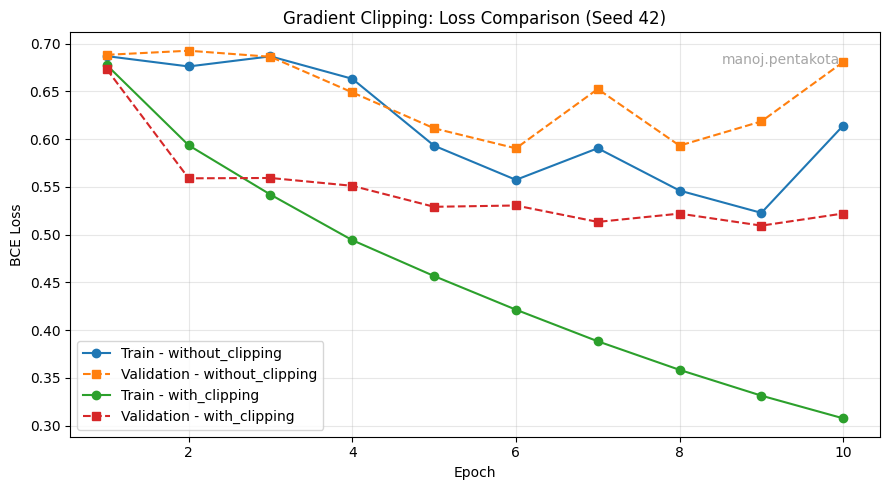

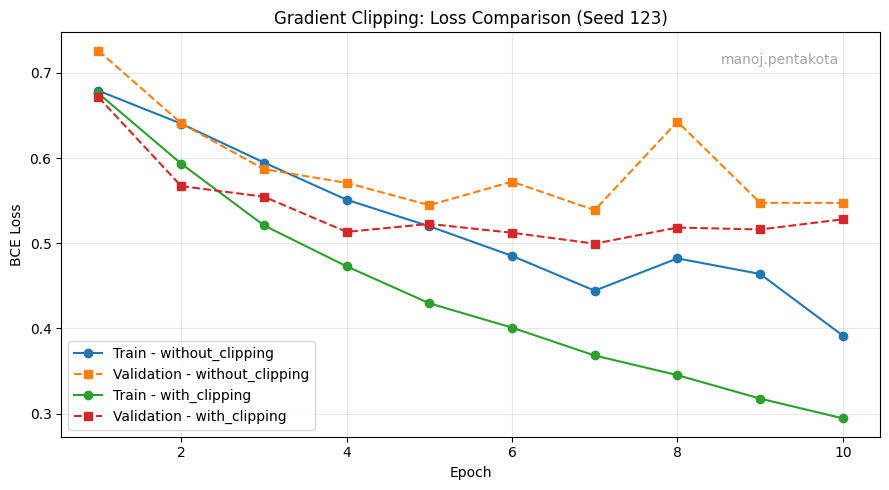

In [86]:
clipping_history_df = pd.DataFrame([
    row
    for result in clipping_results
    for row in result["history"]
])
for seed in CLIP_SEEDS:
    seed_df = clipping_history_df[
        clipping_history_df["seed"] == seed
    ]
    plt.figure(figsize=(9, 5))
    for condition in ["without_clipping", "with_clipping"]:
        condition_df = seed_df[
            seed_df["condition"] == condition
        ]
        plt.plot(
            condition_df["epoch"],
            condition_df["train_loss"],
            marker="o",
            label=f"Train - {condition}"
        )
        plt.plot(
            condition_df["epoch"],
            condition_df["val_loss"],
            marker="s",
            linestyle="--",
            label=f"Validation - {condition}"
        )
    plt.xlabel("Epoch")
    plt.ylabel("BCE Loss")
    plt.title(f"Gradient Clipping: Loss Comparison (Seed {seed})")
    plt.text(
    0.95, 0.95, "manoj.pentakota",
    ha="right",
    va="top",
    transform=plt.gca().transAxes,
    fontsize=10,
    color="gray",
    alpha=0.7
    )
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"/content/gradient_clipping_loss_seed{seed}.png",dpi=200)
    plt.show()

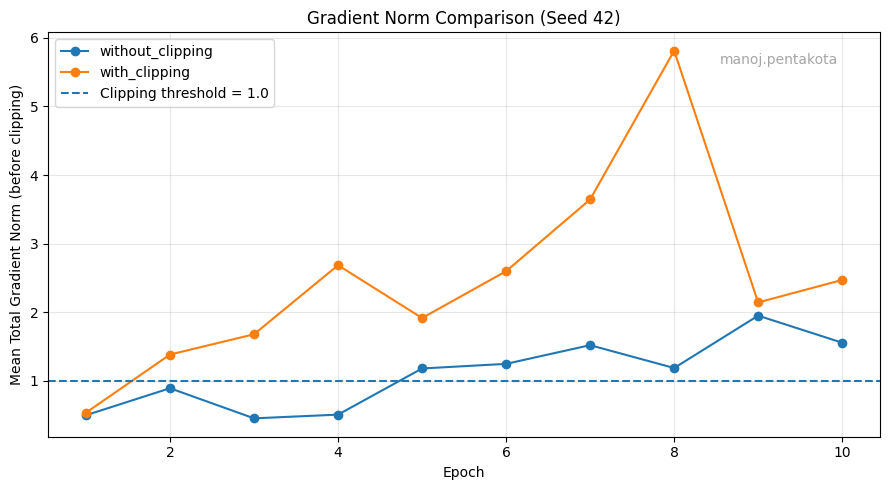

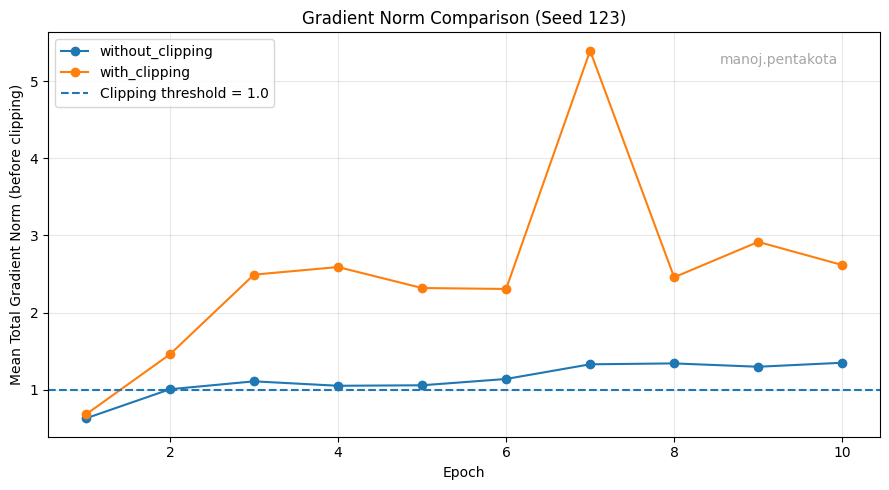

In [87]:
for seed in CLIP_SEEDS:
    seed_df = clipping_history_df[
        clipping_history_df["seed"] == seed
    ]
    plt.figure(figsize=(9, 5))
    for condition in ["without_clipping", "with_clipping"]:
        condition_df = seed_df[
            seed_df["condition"] == condition
        ]
        plt.plot(
            condition_df["epoch"],
            condition_df["mean_gradient_norm"],
            marker="o",
            label=condition
        )
    plt.axhline(
        y=CLIP_MAX_NORM,
        linestyle="--",
        label="Clipping threshold = 1.0"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Mean Total Gradient Norm (before clipping)")
    plt.title(f"Gradient Norm Comparison (Seed {seed})")
    plt.text(
    0.95, 0.95, "manoj.pentakota",
    ha="right",
    va="top",
    transform=plt.gca().transAxes,
    fontsize=10,
    color="gray",
    alpha=0.7
    )
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        f"/content/gradient_clipping_norm_seed{seed}.png",
        dpi=200
    )
    plt.show()

In [88]:
clipping_frequency = clipping_history_df[
    clipping_history_df["condition"] == "with_clipping"
][[
    "seed",
    "epoch",
    "mean_gradient_norm",
    "max_gradient_norm",
    "clipped_fraction"
]]

display(clipping_frequency)

print(
    "Overall fraction of training iterations clipped:",
    clipping_frequency["clipped_fraction"].mean()
)

,seed,epoch,mean_gradient_norm,max_gradient_norm,clipped_fraction
10,42,1,0.535823,2.177882,0.075758
11,42,2,1.383330,22.013433,0.457576
12,42,3,1.678964,12.456808,0.581818
13,42,4,2.685576,191.917160,0.618182
14,42,5,1.915813,25.692934,0.666667
15,42,6,2.597977,64.761314,0.724242
16,42,7,3.643603,343.576538,0.739394
17,42,8,5.811811,1043.090210,0.766667
18,42,9,2.142827,31.509188,0.784848
19,42,10,2.470925,43.873920,0.769697


Overall fraction of training iterations clipped: 0.6540909090909091
